# Land cover from Sentinel-1 radar: earlier attempt (version 3)

**Earlier project stage: 500 locations, single-pass images, first prototype**

Deep Learning · Final project · supporting notebook (archive)

| | |
| --- | --- |
| **Under the guidance of** | Prof. Dr.-Ing. Binh Vu |
| **Submitted by** | Shruti Shankar Bhandari |
| **Course** | Deep Learning, SRH University Heidelberg |
| **Date** | 9 November 2026 |
| **Hardware** | MacBook with Apple Silicon (PyTorch on MPS) |

*Data: Copernicus Sentinel-1 via Google Earth Engine · ESA WorldCover 2021 · CORINE Land Cover 2018*

---

This notebook records the **earlier attempt** of the project (dataset version 3). It is kept as the history that led to the final notebook (`Deep_Learning_final_submission.ipynb`), which uses 370 places, a different split and the ImageNet-initialised FPN. **The numbers of the two notebooks are not comparable and the report's results come from the final notebook.**

> **DO NOT RE-RUN THIS NOTEBOOK. It is a record of a finished run, not a script.** It needs the Google Drive dataset, a local cache and Earth Engine access. The cells that delete files, download data, or train and overwrite model weights are marked *Record only* and are disabled with a safety guard that stops with an error; the original code of the deleting cell is commented out. Do not use *Run All*.

## Contents

| Part | What happens | Main output |
| --- | --- | --- |
| 1 | Setup and Earth Engine access | connection check |
| 2 | Classes and choosing 500 locations | 500 locations, six classes |
| 3 | Download of Sentinel-1 and labels, clean-up | 24,580 single-pass patches |
| 4 | Local cache and data diagnostics, split | 448 locations kept |
| 5 | First models: UNet baseline and FPN | validation mIoU 0.368 and 0.457 |
| 6 | Model choice and the test set | FPN, test mIoU 0.429 (composites) |
| 7 | First prototype runs, majority vote over months | Heidelberg 2025, CORINE comparison |
| 8 | Annual context channels | test mIoU 0.526 |

**What this stage showed:** the architecture hardly matters (FPN minus UNet +0.002 on test composites), the annual context channels help (+0.096 [−0.006, +0.199]), and the models fail in the held-out Australian region. These findings led to the larger dataset, the pre-set rules and the pretrained encoder of the final notebook.

## Part 1: Setup and Earth Engine access

Installs the packages (PyTorch, segmentation-models-pytorch, Earth Engine) and checks the device. The output shows PyTorch 2.15.0, SMP 0.6.0 and the Apple GPU (MPS).

In [1]:
# ═══════════════════════════════════════════════════════════
# LULC Semantic Segmentation using Sentinel-1 SAR Data
# SRH Heidelberg University — Deep Learning
# ═══════════════════════════════════════════════════════════

!pip install segmentation-models-pytorch pytorch-lightning \
    earthengine-api albumentations scipy -q

import ee, os, json, random, time, requests, io, calendar
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
import pytorch_lightning as pl
import albumentations as A
from PIL import Image as PILImage
from collections import Counter, defaultdict
from scipy.ndimage import uniform_filter
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

print(f'✅ PyTorch:    {torch.__version__}')
print(f'✅ SMP:        {smp.__version__}')
print(f'✅ Device:     {"MPS" if torch.backends.mps.is_available() else "CPU"}')


✅ PyTorch:    2.15.0
✅ SMP:        0.6.0
✅ Device:     MPS


Connects to Google Earth Engine, checks the connection, and defines the project folders of this earlier dataset (`dataset_v3`: raw passes, labels, metadata, weights).

In [2]:
# ── Google Earth Engine Authentication ──
from google.auth.transport.requests import Request
from google.oauth2.credentials import Credentials
import subprocess

ee.Authenticate()
ee.Initialize(project='friendly-aurora-426714-v0')

# Verify GEE works
test = ee.Image('NASA/NASADEM_HGT/001').getInfo()
print(f'✅ GEE connected: {test["type"]}')

# ── Paths ──
BASE_DIR     = os.path.expanduser(
    '~/Google Drive/My Drive/LULC_project')
RAW_DIR      = f'{BASE_DIR}/dataset_v3/raw'
PROC_DIR     = f'{BASE_DIR}/dataset_v3/processed'
LABEL_DIR    = f'{BASE_DIR}/dataset_v3/labels'
LABEL7_DIR   = f'{BASE_DIR}/dataset_v3/labels_7class'
META_DIR     = f'{BASE_DIR}/dataset_v3/meta'
WEIGHTS_DIR  = f'{BASE_DIR}/dataset_v3/weights'

for d in [RAW_DIR, PROC_DIR, LABEL_DIR,
          LABEL7_DIR, META_DIR, WEIGHTS_DIR]:
    os.makedirs(d, exist_ok=True)

print(f'✅ All folders ready')
print(f'✅ Base: {BASE_DIR}')

✅ GEE connected: Image
✅ All folders ready
✅ Base: /Users/shrutibhandari/Google Drive/My Drive/LULC_project


## Part 2: Classes and choosing the locations

Defines the six classes (Forest, Shrub/Grass, Cropland, Urban, Bare/Arid, Water/Wetland), their colours and the mapping of the 11 ESA WorldCover classes to these six.

In [3]:
# ── 6-Class Scheme ──
CLASS_NAMES = [
    'Forest',       # 0
    'Shrub/Grass',  # 1
    'Cropland',     # 2
    'Urban',        # 3
    'Bare/Arid',    # 4
    'Water/Wetland' # 5
]

CLASS_COLORS = [
    '#1A5E20',  # Forest       — dark green
    '#FFBB22',  # Shrub/Grass  — yellow
    '#F096FF',  # Cropland     — pink
    '#FA0000',  # Urban        — red
    '#B4B4B4',  # Bare/Arid    — gray
    '#0064C8',  # Water/Wetland— blue
]

# WorldCover 11 → our 6 classes
WORLDCOVER_REMAP = {
    10: 0,   # Tree cover    → Forest
    20: 1,   # Shrubland     → Shrub/Grass
    30: 1,   # Grassland     → Shrub/Grass
    40: 2,   # Cropland      → Cropland
    50: 3,   # Built-up      → Urban
    60: 4,   # Bare veg      → Bare/Arid
    70: 4,   # Snow/ice      → Bare/Arid
    80: 5,   # Water         → Water/Wetland
    90: 5,   # Wetland       → Water/Wetland
    95: 5,   # Mangroves     → Water/Wetland
    100:4,   # Moss/lichen   → Bare/Arid
}

NUM_CLASSES  = 6
IGNORE_INDEX = 255

print('✅ Class scheme defined:')
for i, name in enumerate(CLASS_NAMES):
    print(f'   Class {i}: {name}')

✅ Class scheme defined:
   Class 0: Forest
   Class 1: Shrub/Grass
   Class 2: Cropland
   Class 3: Urban
   Class 4: Bare/Arid
   Class 5: Water/Wetland


Draws 1,001 random locations stratified by biome region and expected class (seed 42): 250 forest, 250 shrub/grass, 150 cropland, 150 bare/arid, 101 urban and 100 water.

In [4]:
# ── Generate 1000 Stratified Random Locations ──
random.seed(42)
np.random.seed(42)

BIOME_REGIONS = {
    'forest': [
        (-10,  0,  -75, -50, 0.25),  # Amazon
        ( -5,  5,   15,  30, 0.20),  # Congo
        (  0,  5,  108, 118, 0.15),  # Borneo
        ( 50, 65,   80, 120, 0.20),  # Siberia
        ( 45, 60,  -90, -70, 0.20),  # Canada boreal
    ],
    'shrub_grass': [
        ( -5, 15,  -18,  40, 0.25),  # African savanna
        (-30,-10,  -65, -45, 0.20),  # South American cerrado
        (-35,-15,  115, 145, 0.20),  # Australian savanna
        ( 40, 55,   50,  90, 0.20),  # Asian steppe
        ( 35, 50, -115, -95, 0.15),  # North American plains
    ],
    'cropland': [
        ( 38, 47,  -98, -85, 0.25),  # US corn belt
        ( 45, 52,   25,  40, 0.25),  # Ukraine/Russia
        ( 20, 35,   70,  90, 0.25),  # India/Pakistan
        ( 30, 40,  105, 125, 0.25),  # China croplands
    ],
    'urban': [
        ( 35, 60,  -10,  40, 0.30),  # Europe
        ( 20, 45,   70, 145, 0.35),  # Asia
        ( 25, 50, -125, -65, 0.20),  # North America
        (-35,  0,  -80, -35, 0.15),  # South America
    ],
    'bare_arid': [
        ( 15, 30,  -15,  35, 0.25),  # Sahara
        ( 20, 30,   40,  60, 0.20),  # Arabia
        ( 35, 45,   55,  95, 0.20),  # Central Asia
        ( 38, 48,   90, 115, 0.20),  # Gobi
        (-30,-15,  -75, -65, 0.15),  # Atacama
    ],
    'water': [
        ( -5,  5,   28,  36, 0.15),  # African lakes
        ( -5,  5,  -60, -50, 0.15),  # Amazon river
        ( 55, 65,   95, 115, 0.15),  # Siberian rivers
        ( 42, 50,   48,  55, 0.15),  # Caspian
        ( 40, 50,  -93, -75, 0.20),  # Great Lakes
        (-20,-10,   30,  36, 0.10),  # African lakes south
        ( 22, 25,   89,  92, 0.10),  # Bangladesh wetlands
    ],
}

TARGET = {
    'forest':     250,
    'shrub_grass':250,
    'cropland':   150,
    'urban':      100,
    'bare_arid':  150,
    'water':      100,
}

LOCATIONS = []
for cls, regions in BIOME_REGIONS.items():
    weights = [r[4] for r in regions]
    total_w = sum(weights)
    weights = [w/total_w for w in weights]

    for i in range(TARGET[cls]):
        idx = np.random.choice(len(regions), p=weights)
        lat_min, lat_max, lon_min, lon_max, _ = regions[idx]
        lat = round(random.uniform(lat_min, lat_max), 4)
        lon = round(random.uniform(lon_min, lon_max), 4)
        LOCATIONS.append({
            'name':  f'{cls}_{i:04d}',
            'lat':   lat,
            'lon':   lon,
            'class': cls,
        })

random.shuffle(LOCATIONS)

# Add Heidelberg explicitly
LOCATIONS.append({
    'name':  'Heidelberg',
    'lat':   49.41,
    'lon':   8.68,
    'class': 'urban'
})

counts = Counter(loc['class'] for loc in LOCATIONS)
print(f'✅ Total locations: {len(LOCATIONS)}')
print(f'✅ Random seed: 42 (reproducible)')
print(f'\nClass distribution:')
for cls, count in sorted(counts.items()):
    bar = '█' * (count // 5)
    print(f'  {cls:15s}: {count:3d} {bar}')

✅ Total locations: 1001
✅ Random seed: 42 (reproducible)

Class distribution:
  bare_arid      : 150 ██████████████████████████████
  cropland       : 150 ██████████████████████████████
  forest         : 250 ██████████████████████████████████████████████████
  shrub_grass    : 250 ██████████████████████████████████████████████████
  urban          : 101 ████████████████████
  water          : 100 ████████████████████


## Part 3: Downloading Sentinel-1 and the labels

Defines the Earth Engine download functions. Terrain correction is applied in Earth Engine before the download, the raw dB values are saved without further processing, and the labels are WorldCover remapped to the six classes. Only the function definitions run here.

In [5]:
# ── GEE Download Functions ──

def terrain_correction(image):
    """
    Apply terrain correction in GEE.
    Must be done before download — needs angle band.
    Removes topographic effects on SAR backscatter.
    """
    angle      = image.select('angle')
    correction = angle.multiply(
        3.14159265/180).cos().multiply(2)
    vv = image.select('VV').subtract(
        correction).rename('VV')
    vh = image.select('VH').subtract(
        correction).rename('VH')
    return image.addBands([vv, vh], overwrite=True)

def get_s1_collection(lon, lat,
                       start='2025-01-01',
                       end='2025-12-31',
                       patch_km=10):
    """
    Get all available S1 images for a location.
    Applies terrain correction in GEE before download.
    """
    point  = ee.Geometry.Point([lon, lat])
    region = point.buffer(patch_km * 500).bounds()

    collection = (ee.ImageCollection('COPERNICUS/S1_GRD')
        .filterDate(start, end)
        .filterBounds(region)
        .filter(ee.Filter.eq('instrumentMode', 'IW'))
        .filter(ee.Filter.listContains(
            'transmitterReceiverPolarisation', 'VV'))
        .filter(ee.Filter.listContains(
            'transmitterReceiverPolarisation', 'VH'))
        .select(['VV', 'VH', 'angle'])
        .map(terrain_correction)
        .select(['VV', 'VH']))

    return collection, region

def download_image(img, region, size=256):
    """Download single S1 image as RAW dB values."""
    try:
        url = img.getDownloadURL({
            'region': region,
            'scale':  10,
            'format': 'NPY',
            'bands':  ['VV', 'VH']
        })
        r   = requests.get(url, timeout=120)
        r.raise_for_status()
        arr = np.load(io.BytesIO(r.content))
        vv  = np.array(PILImage.fromarray(
            arr['VV'].astype(np.float32)).resize(
            (size, size), PILImage.NEAREST))
        vh  = np.array(PILImage.fromarray(
            arr['VH'].astype(np.float32)).resize(
            (size, size), PILImage.NEAREST))
        return np.stack([vv, vh], axis=0)
    except:
        return None

def download_label(region, size=256):
    """Download WorldCover label for a region."""
    try:
        wc  = ee.ImageCollection(
            'ESA/WorldCover/v200').first().clip(region)
        url = wc.getDownloadURL({
            'region': region,
            'scale':  10,
            'format': 'NPY',
            'bands':  ['Map']
        })
        r   = requests.get(url, timeout=120)
        arr = np.load(io.BytesIO(r.content))
        lc  = np.array(PILImage.fromarray(
            arr['Map'].astype(np.float32)).resize(
            (size, size), PILImage.NEAREST))
        return lc.astype(np.uint8)
    except:
        return None

def remap_label(lc_11class):
    """Remap WorldCover 11 classes → 6 classes."""
    remapped = np.full_like(
        lc_11class, IGNORE_INDEX, dtype=np.uint8)
    for orig, new in WORLDCOVER_REMAP.items():
        remapped[lc_11class == orig] = new
    return remapped

print('✅ All download functions ready!')
print('   ✓ Terrain correction: IN GEE (correct)')
print('   ✓ Raw dB values saved (no preprocessing)')
print('   ✓ Labels: WorldCover → 6 classes')

✅ All download functions ready!
   ✓ Terrain correction: IN GEE (correct)
   ✓ Raw dB values saved (no preprocessing)
   ✓ Labels: WorldCover → 6 classes


Selects 500 of the 1,001 locations with a class balance of 125 forest, 125 shrub/grass, 75 cropland, 75 bare/arid, 50 urban and 50 water.

In [6]:
import random
random.seed(42)

TARGET_500 = {
    'forest':     125,
    'shrub_grass':125,
    'cropland':    75,
    'urban':       50,
    'bare_arid':   75,
    'water':       50,
}

from collections import defaultdict
by_class = defaultdict(list)
for loc in LOCATIONS:
    by_class[loc['class']].append(loc)

LOCATIONS_500 = []
for cls, target in TARGET_500.items():
    locs = by_class[cls].copy()
    random.shuffle(locs)
    LOCATIONS_500 += locs[:target]

random.shuffle(LOCATIONS_500)

counts = Counter(loc['class']
                 for loc in LOCATIONS_500)
print(f'✅ Total: {len(LOCATIONS_500)} locations')
for cls, count in sorted(counts.items()):
    print(f'  {cls:15s}: {count}')
print(f'\nExpected patches: ~{len(LOCATIONS_500)*70:,}')
print(f'Est. time: ~{len(LOCATIONS_500)*70*2.5/3600/4:.1f} hours')

✅ Total: 500 locations
  bare_arid      : 75
  cropland       : 75
  forest         : 125
  shrub_grass    : 125
  urban          : 50
  water          : 50

Expected patches: ~35,000
Est. time: ~6.1 hours


> **Record only, do not run.** This cell downloads from Earth Engine (about 7.6 hours).

Downloads the single Sentinel-1 passes and the labels of the 500 locations with four parallel workers. Result: 500 of 500 locations processed, 24,912 patches and 496 labels; 16 downloads failed.

In [7]:
import concurrent.futures
import threading
import time, os, json, requests, io
import numpy as np
from PIL import Image as PILImage

lock         = threading.Lock()
total_done   = 0
total_failed = []

def download_location(loc):
    global total_done, total_failed

    name = loc['name']
    lat  = loc['lat']
    lon  = loc['lon']
    cls  = loc['class']

    loc_raw_dir = f'{RAW_DIR}/{name}'
    os.makedirs(loc_raw_dir, exist_ok=True)

    # Skip if already done
    existing = [f for f in os.listdir(loc_raw_dir)
                if f.endswith('.npy')]
    if len(existing) >= 60:
        with lock:
            total_done += 1
        return len(existing)

    downloaded = len(existing)

    try:
        point  = ee.Geometry.Point([lon, lat])
        region = point.buffer(5000).bounds()

        collection = (ee.ImageCollection(
                'COPERNICUS/S1_GRD')
            .filterDate('2025-01-01','2025-12-31')
            .filterBounds(region)
            .filter(ee.Filter.eq(
                'instrumentMode','IW'))
            .filter(ee.Filter.listContains(
                'transmitterReceiverPolarisation',
                'VV'))
            .filter(ee.Filter.listContains(
                'transmitterReceiverPolarisation',
                'VH'))
            .select(['VV','VH','angle'])
            .map(terrain_correction)
            .select(['VV','VH']))

        total_available = collection.size().getInfo()

        if total_available == 0:
            with lock:
                total_done  += 1
                total_failed.append(name)
            json.dump({
                'name':name,'lat':lat,'lon':lon,
                'class':cls,'downloaded':0,
                'status':'no_images'
            }, open(f'{META_DIR}/{name}.json','w'))
            return 0

        n_download = min(total_available, 100)
        img_list   = collection.toList(n_download)

        for i in range(n_download):
            img   = ee.Image(img_list.get(i))
            date  = img.date().format(
                'YYYY-MM-dd').getInfo()
            orbit = img.get(
                'orbitProperties_pass').getInfo()
            o_s   = 'D' if orbit=='DESCENDING' \
                    else 'A'
            fname = f'{date}_{o_s}.npy'
            fpath = f'{loc_raw_dir}/{fname}'

            if os.path.exists(fpath):
                downloaded += 1
                continue

            try:
                url = img.getDownloadURL({
                    'region': region,
                    'scale':  10,
                    'format': 'NPY',
                    'bands':  ['VV','VH']
                })
                r   = requests.get(
                    url, timeout=120)
                r.raise_for_status()
                arr = np.load(
                    io.BytesIO(r.content))
                vv  = np.array(PILImage.fromarray(
                    arr['VV'].astype(np.float32)
                ).resize((256,256),
                          PILImage.NEAREST))
                vh  = np.array(PILImage.fromarray(
                    arr['VH'].astype(np.float32)
                ).resize((256,256),
                          PILImage.NEAREST))
                np.save(fpath,
                    np.stack([vv,vh], axis=0))
                downloaded += 1
                time.sleep(0.3)
            except:
                time.sleep(1)
                continue

    except Exception as e:
        with lock:
            total_done  += 1
            total_failed.append(name)
        return 0

    # Download label
    label_path  = f'{LABEL_DIR}/{name}_lc.npy'
    label7_path = f'{LABEL7_DIR}/{name}_lc6.npy'

    if not os.path.exists(label_path):
        try:
            point  = ee.Geometry.Point([lon, lat])
            region = point.buffer(5000).bounds()
            wc  = ee.ImageCollection(
                'ESA/WorldCover/v200').first(
                ).clip(region)
            url = wc.getDownloadURL({
                'region':region,'scale':10,
                'format':'NPY','bands':['Map']})
            r   = requests.get(url, timeout=120)
            arr = np.load(io.BytesIO(r.content))
            lc  = np.array(PILImage.fromarray(
                arr['Map'].astype(np.float32)
            ).resize((256,256), PILImage.NEAREST))
            lc  = lc.astype(np.uint8)
            np.save(label_path, lc)
            np.save(label7_path, remap_label(lc))
        except:
            pass

    # Save metadata
    json.dump({
        'name':            name,
        'lat':             lat,
        'lon':             lon,
        'class':           cls,
        'total_available': total_available,
        'downloaded':      downloaded,
        'status':          'complete'
    }, open(f'{META_DIR}/{name}.json','w'))

    with lock:
        total_done += 1
        if downloaded == 0:
            total_failed.append(name)
        if total_done % 10 == 0:
            total_raw = sum(
                len(os.listdir(f'{RAW_DIR}/{d}'))
                for d in os.listdir(RAW_DIR)
                if os.path.isdir(
                    f'{RAW_DIR}/{d}'))
            labels = len(os.listdir(LABEL_DIR))
            pct    = total_done/len(
                LOCATIONS_500)*100
            print(
                f'[{total_done:3d}/'
                f'{len(LOCATIONS_500)}] '
                f'{pct:5.1f}% | '
                f'{cls:12s} | '
                f'✅ {name:20s} | '
                f'imgs:{downloaded:3d} | '
                f'raw:{total_raw:6d} | '
                f'labels:{labels:3d}')

    return downloaded

# ── RUN ──
NUM_WORKERS  = 4
total_done   = 0
total_failed = []

print(f' Downloading 500 locations!')
print(f'   Locations: {len(LOCATIONS_500)}')
print(f'   Img/loc:   ~70 individual passes')
print(f'   Workers:   {NUM_WORKERS}')
print(f'   Expected:  ~{len(LOCATIONS_500)*70:,} patches')
print(f'   Est. time: ~{len(LOCATIONS_500)*70*2.5/3600/NUM_WORKERS:.1f} hours\n')

start_time = time.time()

with concurrent.futures.ThreadPoolExecutor(
        max_workers=NUM_WORKERS) as executor:
    futures = {
        executor.submit(download_location, loc): loc
        for loc in LOCATIONS_500
    }
    for future in concurrent.futures.as_completed(
            futures):
        try:
            future.result()
        except Exception as e:
            loc = futures[future]
            print(f'❌ {loc["name"]}: {e}')

elapsed   = time.time() - start_time
total_raw = sum(
    len(os.listdir(f'{RAW_DIR}/{d}'))
    for d in os.listdir(RAW_DIR)
    if os.path.isdir(f'{RAW_DIR}/{d}'))

print(f'\n Complete!')
print(f'   Time:    {elapsed/3600:.1f} hours')
print(f'✅ Done:    {total_done}/{len(LOCATIONS_500)}')
print(f'⚠️  Failed: {len(total_failed)}')
print(f'✅ Patches: {total_raw:,}')
print(f'✅ Labels:  {len(os.listdir(LABEL_DIR))}')

   Locations: 500
   Img/loc:   ~70 individual passes
   Workers:   4
   Expected:  ~35,000 patches
   Est. time: ~6.1 hours

[ 10/500]   2.0% | forest       | ✅ forest_0236          | imgs: 60 | raw:   987 | labels: 38
[ 20/500]   4.0% | water        | ✅ water_0065           | imgs: 33 | raw:  1454 | labels: 46
[ 30/500]   6.0% | shrub_grass  | ✅ shrub_grass_0087     | imgs: 38 | raw:  1894 | labels: 56
[ 40/500]   8.0% | forest       | ✅ forest_0194          | imgs: 70 | raw:  2476 | labels: 66
[ 50/500]  10.0% | urban        | ✅ urban_0068           | imgs:100 | raw:  3046 | labels: 75
[ 60/500]  12.0% | forest       | ✅ forest_0120          | imgs: 22 | raw:  3495 | labels: 84
[ 70/500]  14.0% | cropland     | ✅ cropland_0060        | imgs:100 | raw:  3816 | labels: 93
[ 80/500]  16.0% | shrub_grass  | ✅ shrub_grass_0231     | imgs: 30 | raw:  4415 | labels:101
[ 90/500]  18.0% | water        | ✅ water_0029           | imgs:100 | raw:  4878 | labels:111
[100/500]  20.0% | water    

### Inventory and clean-up of the download

Counts the raw folders and labels: 512 raw folders, 496 labels, 495 usable locations.

In [8]:
import os

raw_locs = [d for d in os.listdir(RAW_DIR) if os.path.isdir(f'{RAW_DIR}/{d}')]
lc11 = {f.replace('_lc.npy','')  for f in os.listdir(LABEL_DIR)}
lc6  = {f.replace('_lc6.npy','') for f in os.listdir(LABEL7_DIR)}

print(f'Raw location folders: {len(raw_locs)}')
print(f'11-class labels:      {len(lc11)}')
print(f'6-class labels:       {len(lc6)}')
print(f'11-class without 6-class: {len(lc11 - lc6)}')

# Locations usable for training: have images AND a 6-class label
usable = [d for d in raw_locs if d in lc6 and len(os.listdir(f'{RAW_DIR}/{d}')) > 0]
print(f'Usable locations:     {len(usable)}')

Raw location folders: 512
11-class labels:      496
6-class labels:       496
11-class without 6-class: 0
Usable locations:     495


Looks for folders outside the chosen 500 (12 found) and for composite files that an earlier download step had left in the raw folders (332).

In [9]:
keep = {l['name'] for l in LOCATIONS_500}
extra = [d for d in os.listdir(RAW_DIR)
         if os.path.isdir(f'{RAW_DIR}/{d}') and d not in keep]
print(f'Folders not in LOCATIONS_500: {len(extra)}')

comp = 0
for d in os.listdir(RAW_DIR):
    p = f'{RAW_DIR}/{d}'
    if os.path.isdir(p):
        comp += sum('composite' in f for f in os.listdir(p))
print(f'Composite files found: {comp}')

Folders not in LOCATIONS_500: 12
Composite files found: 332


Splits those composite files into those inside the chosen 500 locations (213 files in 20 locations) and those in the 12 extra folders (119 files).

In [10]:
keep = {l['name'] for l in LOCATIONS_500}

comp_keep, comp_extra = [], []
for d in os.listdir(RAW_DIR):
    p = f'{RAW_DIR}/{d}'
    if not os.path.isdir(p):
        continue
    for f in os.listdir(p):
        if 'composite' in f:
            (comp_keep if d in keep else comp_extra).append(f'{p}/{f}')

print(f'Composites in chosen 500 folders: {len(comp_keep)}')
print(f'Composites in the 12 extra folders: {len(comp_extra)}')

# Which chosen locations are affected?
affected = sorted({os.path.basename(os.path.dirname(f)) for f in comp_keep})
print(f'Chosen locations with composites: {len(affected)}')
for name in affected[:10]:
    files = os.listdir(f'{RAW_DIR}/{name}')
    n_c = sum('composite' in f for f in files)
    print(f'  {name:20s} passes={len(files)-n_c:3d} composites={n_c}')

Composites in chosen 500 folders: 213
Composites in the 12 extra folders: 119
Chosen locations with composites: 20
  bare_arid_0093       passes=100 composites=12
  cropland_0023        passes= 29 composites=12
  cropland_0041        passes= 59 composites=11
  cropland_0045        passes= 99 composites=8
  cropland_0104        passes= 53 composites=12
  cropland_0116        passes= 32 composites=11
  forest_0028          passes= 30 composites=12
  forest_0083          passes= 29 composites=12
  forest_0096          passes= 56 composites=12
  forest_0103          passes= 30 composites=12


> **Record only, do not run.** The original code deleted the 332 stray composite files. It is disabled and commented out.

Output: 332 files deleted.

In [11]:
# RECORD ONLY: this cell was run once during the earlier attempt and is disabled. Do not run it again (it deletes the composite files).
raise RuntimeError('RECORD ONLY: this cell deletes files. It was run once and is disabled.')
# --- original code below, kept as a record of what was run ---
# DELETE = True
# for f in comp_keep + comp_extra:
#     if DELETE:
#         os.remove(f)
# print(f'Deleted {len(comp_keep)+len(comp_extra)} files')

Deleted 332 files


Tops up the 20 affected locations by downloading their single passes again, so that the raw folders hold single passes only.

In [12]:
affected_locs = [l for l in LOCATIONS_500 if l['name'] in set(affected)]
print(f'Topping up {len(affected_locs)} locations')

before = {l['name']: len(os.listdir(f'{RAW_DIR}/{l["name"]}')) for l in affected_locs}

total_done, total_failed = 0, []
with concurrent.futures.ThreadPoolExecutor(max_workers=4) as ex:
    list(ex.map(download_location, affected_locs))

for l in affected_locs:
    n = len(os.listdir(f'{RAW_DIR}/{l["name"]}'))
    if n != before[l['name']]:
        print(f'  {l["name"]:20s} {before[l["name"]]} -> {n}')
print('Done')

Topping up 20 locations
[ 20/500]   4.0% | cropland     | ✅ cropland_0104        | imgs:106 | raw: 24580 | labels:496
Done


Counts the single-pass patches of the chosen 500 locations: **24,580**.

In [13]:
real = sum(
    len([f for f in os.listdir(f'{RAW_DIR}/{l["name"]}') if f.endswith('.npy')])
    for l in LOCATIONS_500 if os.path.isdir(f'{RAW_DIR}/{l["name"]}')
)
print(f'Real single-pass patches (500 chosen locations): {real:,}')

Real single-pass patches (500 chosen locations): 24,580


### Label shares and raw-data checks

Class shares of the labelled pixels (Forest 35.9%, Shrub/Grass 24.0%, Cropland 13.4%, Urban 1.1%, Bare/Arid 15.9%, Water/Wetland 9.8%; 6.0% unlabelled) and a check of 200 raw files for zeros and NaN values.

In [14]:
from collections import Counter
import random

usable = [l['name'] for l in LOCATIONS_500
          if os.path.exists(f'{LABEL7_DIR}/{l["name"]}_lc6.npy')]

cnt, nodata, total = Counter(), 0, 0
for n in usable:
    lc = np.load(f'{LABEL7_DIR}/{n}_lc6.npy')
    total += lc.size; nodata += int((lc == 255).sum())
    for c in range(6): cnt[c] += int((lc == c).sum())
valid = sum(cnt.values())
for c, name in enumerate(CLASS_NAMES):
    print(f'{name:15s} {cnt[c]/valid*100:5.1f}%')
print(f'unlabelled (255): {nodata/total*100:.1f}%')

random.seed(0)
zero_files = nan_files = checked = 0
for n in random.sample(usable, 40):
    fs = [f for f in os.listdir(f'{RAW_DIR}/{n}') if f.endswith('.npy')][:5]
    for f in fs:
        a = np.load(f'{RAW_DIR}/{n}/{f}')
        zero_files += int((a == 0).mean() > 0.01)
        nan_files  += int(np.isnan(a).any())
        checked += 1
print(f'raw files checked: {checked} | >1% exact zeros: {zero_files} | with NaN: {nan_files}')

Forest           35.9%
Shrub/Grass      24.0%
Cropland         13.4%
Urban             1.1%
Bare/Arid        15.9%
Water/Wetland     9.8%
unlabelled (255): 6.0%
raw files checked: 200 | >1% exact zeros: 16 | with NaN: 0


## Part 4: Local cache and data diagnostics

> **Record only, do not run.** Rebuilds the local cache.

Builds the local training cache for 478 locations: single passes, monthly composites and metadata.

In [15]:
# RECORD ONLY: this cell was run once during the earlier attempt and is disabled. Do not run it again (it rebuilds the local cache).
raise RuntimeError('RECORD ONLY: this cell writes or overwrites files. It was run once and is disabled.')
# --- original code below, kept as a record of what was run ---
import os, json, time, warnings
import numpy as np, pandas as pd
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

BASE_DIR = os.path.expanduser('~/Google Drive/My Drive/LULC_project')
RAW_DIR  = f'{BASE_DIR}/dataset_v3/raw'
LOCAL    = os.path.expanduser('~/lulc_local/d2025')
for s in ('singles', 'composites', 'meta', 'labels', 'weights'):
    os.makedirs(f'{LOCAL}/{s}', exist_ok=True)

LIMIT = None          # None = all locations

summ  = pd.read_csv('locations_500_summary.csv')
names = summ[summ['ok']]['name'].tolist()

def process(name):
    mp = f'{LOCAL}/meta/{name}.json'
    if os.path.exists(mp):
        return name, 'skip'
    src = f'{RAW_DIR}/{name}'
    files = sorted(f for f in os.listdir(src) if f.endswith('.npy') and 'composite' not in f)
    singles, by_month, dropped = [], {}, 0
    for f in files:
        try:
            a = np.load(f'{src}/{f}').astype(np.float32)
        except Exception:
            dropped += 1; continue
        if a.shape != (2, 256, 256):
            dropped += 1; continue
        a[:, (a == 0).any(axis=0)] = np.nan        # masked pixels were saved as exact zeros
        a = np.clip(a, -60, 40)                    # NaN stays NaN
        if np.isnan(a).mean() > 0.5:               # mostly no-data
            dropped += 1; continue
        singles.append(a)
        by_month.setdefault(int(f[5:7]), []).append(a)   # filename: YYYY-MM-DD_X.npy
    if not singles:
        return name, 'no valid patches'
    np.save(f'{LOCAL}/singles/{name}.npy', np.stack(singles).astype(np.float16))
    months = sorted(by_month)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        comp = np.stack([np.nanmedian(np.stack(by_month[m]), axis=0) for m in months])
    np.save(f'{LOCAL}/composites/{name}.npy', comp.astype(np.float16))
    json.dump({'n_singles': len(singles), 'months': months, 'dropped': dropped}, open(mp, 'w'))
    return name, f'{len(singles)} singles, {len(months)} composites, {dropped} dropped'

todo = names[:LIMIT] if LIMIT else names
t0 = time.time()
with ThreadPoolExecutor(6) as ex:
    for name, status in tqdm(ex.map(process, todo), total=len(todo)):
        if LIMIT:
            print(name, status)
dt = time.time() - t0
print(f'{len(todo)} locations in {dt/60:.1f} min -> {dt/len(todo):.1f} s/location')
print(f'estimated for all {len(names)}: {dt/len(todo)*len(names)/60:.0f} min')

100%|██████████| 478/478 [00:23<00:00, 20.75it/s]

478 locations in 0.4 min -> 0.0 s/location
estimated for all 478: 0 min


Checks the cache: 475 locations with singles, composites and metadata, 22,400 single-pass patches kept and 2,048 dropped (wrong shape or more than 50% no data), 188 locations with fewer than 12 composite months, 6.7 GB on local disk.

In [16]:
import os, json, numpy as np

LOCAL = os.path.expanduser('~/lulc_local/d2025')
sing = sorted(f[:-4] for f in os.listdir(f'{LOCAL}/singles') if f.endswith('.npy'))
comp = sorted(f[:-4] for f in os.listdir(f'{LOCAL}/composites') if f.endswith('.npy'))
meta = sorted(f[:-5] for f in os.listdir(f'{LOCAL}/meta') if f.endswith('.json'))
print(f'singles {len(sing)} | composites {len(comp)} | meta {len(meta)}  (expect 478 each)')

tot = drop = 0
nomonth = []
for n in meta:
    m = json.load(open(f'{LOCAL}/meta/{n}.json'))
    tot += m['n_singles']; drop += m['dropped']
    if len(m['months']) < 12: nomonth.append((n, len(m['months'])))
print(f'single-pass patches kept: {tot:,} | dropped (bad shape / >50% no-data): {drop}')
print(f'locations with fewer than 12 composite months: {len(nomonth)}', nomonth[:5])

size_gb = sum(os.path.getsize(f'{LOCAL}/{d}/{f}') for d in ('singles', 'composites')
              for f in os.listdir(f'{LOCAL}/{d}')) / 1024**3
print(f'size on local disk: {size_gb:.1f} GB')

# value sanity on a few random files
rng = np.random.default_rng(0)
for n in rng.choice(sing, 6, replace=False):
    a = np.load(f'{LOCAL}/singles/{n}.npy', mmap_mode='r')
    x = np.array(a[0], dtype=np.float32)
    print(f'{n:18s} shape {a.shape} | NaN {np.isnan(x).mean()*100:4.1f}% | '
          f'VV {np.nanmean(x[0]):6.1f} | VH {np.nanmean(x[1]):6.1f} dB')

singles 475 | composites 475 | meta 475  (expect 478 each)
single-pass patches kept: 22,400 | dropped (bad shape / >50% no-data): 2048
locations with fewer than 12 composite months: 188 [('bare_arid_0002', 10), ('bare_arid_0010', 3), ('bare_arid_0018', 9), ('bare_arid_0022', 9), ('bare_arid_0035', 10)]
size on local disk: 6.7 GB
cropland_0112      shape (73, 2, 256, 256) | NaN 44.5% | VV  -16.4 | VH  -26.6 dB
shrub_grass_0081   shape (43, 2, 256, 256) | NaN  0.0% | VV  -13.4 | VH  -22.8 dB
forest_0205        shape (48, 2, 256, 256) | NaN  0.0% | VV  -13.0 | VH  -19.2 dB
cropland_0145      shape (18, 2, 256, 256) | NaN  0.0% | VV  -11.6 | VH  -17.7 dB
bare_arid_0039     shape (36, 2, 256, 256) | NaN  0.0% | VV  -11.3 | VH  -17.3 dB
urban_0051         shape (76, 2, 256, 256) | NaN  0.0% | VV  -25.7 | VH  -43.4 dB


Backscatter statistics per class: the distribution of the patch mean VH (dB) by class, the share of very dark patches, and locations with fewer than 12 months although more than 100 passes were available.

In [17]:
import os, json, warnings
import numpy as np, pandas as pd
warnings.filterwarnings('ignore')

BASE_DIR = os.path.expanduser('~/Google Drive/My Drive/LULC_project')
LOCAL    = os.path.expanduser('~/lulc_local/d2025')
summ = pd.read_csv('locations_500_summary.csv').set_index('name')
sing = sorted(f[:-4] for f in os.listdir(f'{LOCAL}/singles') if f.endswith('.npy'))

rows = []
for n in sing:
    a = np.load(f'{LOCAL}/singles/{n}.npy').astype(np.float32)        # (k, 2, 256, 256)
    vv, vh = np.nanmean(a[:, 0], axis=(1, 2)), np.nanmean(a[:, 1], axis=(1, 2))
    low  = np.nanmean(a[:, 1] < -35, axis=(1, 2))                      # share of pixels with VH < -35 dB
    nanf = np.isnan(a[:, 0]).mean(axis=(1, 2))
    for i in range(len(a)):
        rows.append((n, i, vv[i], vh[i], low[i], nanf[i]))
p = pd.DataFrame(rows, columns=['name', 'i', 'vv', 'vh', 'low35', 'nanf'])
p['cls'] = p.name.map(summ['class'])

print('per-patch mean VH (dB) by class:')
print(p.groupby('cls').vh.describe(percentiles=[.05, .25, .5, .75, .95]).round(1)
        [['count', '5%', '25%', '50%', '75%', '95%']])
print('\nshare of patches with mean VH < -35 dB, or >50% of pixels below -35 dB:')
p['suspect'] = (p.vh < -35) | (p.low35 > 0.5)
print((p.groupby('cls').suspect.mean() * 100).round(1))
print(f'\noverall suspect share: {p.suspect.mean()*100:.1f}%  ({int(p.suspect.sum()):,} patches)')

print('\nlocations with the highest suspect share:')
bad = p.groupby('name').suspect.agg(['mean', 'sum', 'size']).sort_values('mean', ascending=False)
print(bad.head(10).assign(cls=lambda d: d.index.map(summ['class'])).round(2))

print('\nurban_0051, per-patch mean VH (dB), in file order:')
print(np.round(p[p.name == 'urban_0051'].vh.values, 0).tolist())

# are short-month locations the ones with many passes available?
tav = {}
for n in sing:
    f = f'{BASE_DIR}/dataset_v3/meta/{n}.json'
    if os.path.exists(f):
        tav[n] = json.load(open(f)).get('total_available')
nm = {n: len(json.load(open(f'{LOCAL}/meta/{n}.json'))['months']) for n in sing}
m = pd.DataFrame({'months': pd.Series(nm), 'avail': pd.Series(tav)}).dropna()
m['short'] = m.months < 12
m['avail>100'] = m.avail > 100
print('\nlocations with < 12 months vs more than 100 passes available:')
print(pd.crosstab(m['short'], m['avail>100']))

per-patch mean VH (dB) by class:
              count    5%   25%   50%   75%   95%
cls                                              
bare_arid    3916.0 -40.6 -36.1 -29.1 -23.3 -17.7
cropland     3831.0 -36.0 -24.8 -21.1 -19.0 -17.0
forest       4092.0 -37.5 -20.4 -16.7 -16.0 -15.5
shrub_grass  5025.0 -38.9 -29.7 -24.0 -18.9 -16.1
urban        2985.0 -40.8 -37.2 -25.6 -18.6 -16.4
water        2551.0 -41.2 -36.7 -20.2 -17.3 -15.7

share of patches with mean VH < -35 dB, or >50% of pixels below -35 dB:
cls
bare_arid      30.4
cropland        5.5
forest          5.8
shrub_grass     8.3
urban          33.3
water          30.1
Name: suspect, dtype: float64

overall suspect share: 17.0%  (3,816 patches)

locations with the highest suspect share:
                  mean  sum  size          cls
name                                          
bare_arid_0085     1.0   85    85    bare_arid
bare_arid_0146     1.0   67    67    bare_arid
shrub_grass_0241   1.0   24    24  shrub_grass
bare_arid_0051 

Compares image and label: backscatter percentiles by label class, and examples where the label disagrees with the image (for example locations tagged urban whose label is water or bare). This is the basis for dropping badly labelled locations in the next cell.

In [18]:
import os, json, warnings
import numpy as np, pandas as pd
warnings.filterwarnings('ignore')

BASE_DIR = os.path.expanduser('~/Google Drive/My Drive/LULC_project')
LAB_DIR  = f'{BASE_DIR}/dataset_v3/labels_7class'
RAW_DIR  = f'{BASE_DIR}/dataset_v3/raw'
LOCAL    = os.path.expanduser('~/lulc_local/d2025')
NAMES    = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
summ = pd.read_csv('locations_500_summary.csv').set_index('name')
sing = sorted(f[:-4] for f in os.listdir(f'{LOCAL}/singles') if f.endswith('.npy'))
rng  = np.random.default_rng(0)

rows, pix = [], {c: ([], []) for c in range(6)}
for n in sing:
    a = np.load(f'{LOCAL}/singles/{n}.npy', mmap_mode='r')
    y = np.load(f'{LAB_DIR}/{n}_lc6.npy')
    v = y[y != 255]
    frac = np.bincount(v, minlength=6) / max(v.size, 1)
    pvh = np.nanmean(np.array(a[:, 1], dtype=np.float32), axis=(1, 2))
    rows.append({'name': n, 'tag': summ.loc[n, 'class'], 'vh_med': np.nanmedian(pvh),
                 'susp': float((pvh < -35).mean()), 'nolabel': float((y == 255).mean()),
                 **{f'L{c}': frac[c] for c in range(6)}})
    for i in rng.choice(len(a), size=min(3, len(a)), replace=False):
        p = np.array(a[i], dtype=np.float32)
        for c in range(6):
            m = (y == c) & ~np.isnan(p[0])
            k = int(m.sum())
            if k:
                s = rng.choice(k, size=min(500, k), replace=False)
                pix[c][0].append(p[0][m][s]); pix[c][1].append(p[1][m][s])
d = pd.DataFrame(rows)
lc = [f'L{c}' for c in range(6)]

print('1) image vs label: backscatter percentiles (dB) by LABEL class (3 patches per location)')
for c in range(6):
    if pix[c][0]:
        vv, vh = np.concatenate(pix[c][0]), np.concatenate(pix[c][1])
        print(f'  {NAMES[c]:14s} n={len(vv):7d} | VV p10/50/90: {np.percentile(vv,[10,50,90]).round(1)} '
              f'| VH p10/50/90: {np.percentile(vh,[10,50,90]).round(1)}')

hi = d[d.susp > 0.8]
print(f'\n2) locations with >80% suspect patches: {len(hi)} of {len(d)}')
print('   mean label mix of these locations (%):', dict(zip(NAMES, (hi[lc].mean().values*100).round(0))))
print('   mean label mix of all other locations (%):', dict(zip(NAMES, (d[d.susp <= .8][lc].mean().values*100).round(0))))
print('   by region tag:'); print(hi.tag.value_counts().to_dict())

print('\n3) forest/urban-tagged locations that are mostly dark:')
chk = d[(d.tag.isin(['forest', 'urban'])) & (d.susp > 0.8)].head(8)
for r in chk.itertuples():
    print(f'  {r.name:14s} tag={r.tag:6s} median VH {r.vh_med:5.1f} | label: ' +
          ', '.join(f'{NAMES[c]} {getattr(r, "L"+str(c))*100:.0f}%' for c in range(6) if getattr(r, "L"+str(c)) > .02) +
          f' | unlabelled {r.nolabel*100:.0f}%')

print('\n4) urban_0051 by orbit direction:')
mm = json.load(open(f'{LOCAL}/meta/urban_0051.json'))
fs = sorted(f for f in os.listdir(f'{RAW_DIR}/urban_0051') if f.endswith('.npy') and 'composite' not in f)
a = np.load(f'{LOCAL}/singles/urban_0051.npy', mmap_mode='r')
if mm['dropped'] == 0 and len(fs) == len(a):
    orb = np.array([f.split('_')[1][0] for f in fs])
    vh = np.nanmean(np.array(a[:, 1], dtype=np.float32), axis=(1, 2))
    for o in ('A', 'D'):
        print(f'  {o}: n={int((orb==o).sum())} mean VH {np.nanmean(vh[orb==o]):.1f} dB')
else:
    print('  filenames cannot be matched to patches (some were dropped), skipping')

1) image vs label: backscatter percentiles (dB) by LABEL class (3 patches per location)
  Forest         n= 472067 | VV p10/50/90: [-15.9 -11.4  -7.3] | VH p10/50/90: [-23.2 -17.6 -13.7]
  Shrub/Grass    n= 506944 | VV p10/50/90: [-19.6 -13.6  -8.8] | VH p10/50/90: [-29.9 -20.5 -15.1]
  Cropland       n= 246962 | VV p10/50/90: [-18.6 -13.5  -9.1] | VH p10/50/90: [-29.7 -21.  -15.7]
  Urban          n= 182045 | VV p10/50/90: [-17.  -11.7  -6. ] | VH p10/50/90: [-25.9 -18.8 -13.8]
  Bare/Arid      n= 257273 | VV p10/50/90: [-23.  -15.4  -9. ] | VH p10/50/90: [-37.6 -24.7 -16.8]
  Water/Wetland  n= 289961 | VV p10/50/90: [-26.4 -18.  -10.4] | VH p10/50/90: [-42.8 -27.4 -17.1]

2) locations with >80% suspect patches: 61 of 475
   mean label mix of these locations (%): {'Forest': np.float64(0.0), 'Shrub/Grass': np.float64(0.0), 'Cropland': np.float64(0.0), 'Urban': np.float64(0.0), 'Bare/Arid': np.float64(20.0), 'Water/Wetland': np.float64(48.0)}
   mean label mix of all other locations (%)

### Split

> **Record only, do not run.** Overwrites `split_2025.csv` and `stats.json`.

Drops 27 locations with more than 80% unlabelled pixels (open sea or no WorldCover), keeps **448** locations, and splits them into train, validation and test by region, with an Australian region test set of 27 locations. Saves the split and the normalisation statistics (mean −13.98 and −22.76 dB, std 5.74 and 8.93).

In [19]:
# RECORD ONLY: this cell was run once during the earlier attempt and is disabled. Do not run it again (it overwrites split_2025.csv and stats.json).
raise RuntimeError('RECORD ONLY: this cell writes or overwrites files. It was run once and is disabled.')
# --- original code below, kept as a record of what was run ---
import os, json, shutil
import numpy as np, pandas as pd

BASE_DIR = os.path.expanduser('~/Google Drive/My Drive/LULC_project')
LAB_DIR  = f'{BASE_DIR}/dataset_v3/labels_7class'     # holds the 6-class labels (*_lc6.npy)
LOCAL    = os.path.expanduser('~/lulc_local/d2025')
NAMES    = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
MAX_UNLABELLED = 0.8

# ── 1) locations that were preprocessed and passed the earlier checks ──
have = {f[:-4] for f in os.listdir(f'{LOCAL}/singles') if f.endswith('.npy')}
df = pd.read_csv('locations_500_summary.csv')
df = df[df['ok'] & df['name'].isin(have)].reset_index(drop=True)

# ── 2) drop open-sea / no-data locations (label mostly 255) ──
unl = {n: float((np.load(f'{LAB_DIR}/{n}_lc6.npy') == 255).mean()) for n in df['name']}
df['unlabelled'] = df['name'].map(unl)
drop = df[df['unlabelled'] > MAX_UNLABELLED]
print(f'dropping {len(drop)} locations with >{MAX_UNLABELLED*100:.0f}% unlabelled pixels '
      f'(open sea / no WorldCover): {drop["class"].value_counts().to_dict()}')
df = df[df['unlabelled'] <= MAX_UNLABELLED].reset_index(drop=True)

# ── 3) copy labels to local disk, read patch counts ──
os.makedirs(f'{LOCAL}/labels', exist_ok=True)
for n in df['name']:
    dst = f'{LOCAL}/labels/{n}.npy'
    if not os.path.exists(dst):
        shutil.copy(f'{LAB_DIR}/{n}_lc6.npy', dst)
df['n_singles'] = [json.load(open(f'{LOCAL}/meta/{n}.json'))['n_singles'] for n in df['name']]

# ── 4) split by 5-degree block; Australia is an extra held-out region ──
aus = df['lat'].between(-45, -10) & df['lon'].between(112, 155)
df['split'] = ''
df.loc[aus, 'split'] = 'region_test'
rest = df[~aus]
rng = np.random.default_rng(42)
vc = rest['block'].value_counts()
order = vc.index.to_numpy()[rng.permutation(len(vc))]
goal, got, assign = {'train': .70, 'val': .15, 'test': .15}, {'train': 0, 'val': 0, 'test': 0}, {}
for b in order:
    k = max(goal, key=lambda s: goal[s] * len(rest) - got[s])
    assign[b] = k; got[k] += vc[b]
df.loc[~aus, 'split'] = df.loc[~aus, 'block'].map(assign)

print(f'\nlocations kept: {len(df)}')
print('\nlocations per region tag and split:')
print(pd.crosstab(df['class'], df['split'], margins=True))
print('\nsingle-pass patches per split:'); print(df.groupby('split')['n_singles'].sum())
thin = pd.crosstab(df['class'], df['split']).drop(columns='region_test', errors='ignore')
if (thin < 5).any().any():
    print('\nWARNING: fewer than 5 locations in some tag/split cells:')
    print(thin[(thin < 5).any(axis=1)])

# ── 5) normalization statistics from TRAIN only (dB, NaN ignored) ──
tr = df[df['split'] == 'train']['name'].tolist()
rng = np.random.default_rng(0)
samp = []
for n in rng.choice(tr, size=min(len(tr), 250), replace=False):
    a = np.load(f'{LOCAL}/singles/{n}.npy', mmap_mode='r')
    idx = np.sort(rng.choice(len(a), size=min(3, len(a)), replace=False))
    samp.append(np.array(a[idx], dtype=np.float32))
S = np.concatenate(samp)
mean = np.nanmean(S, axis=(0, 2, 3)).tolist()
std  = np.nanstd(S,  axis=(0, 2, 3)).tolist()
del S

# ── 6) class weights from TRAIN labels only ──
cnt = np.zeros(6)
for n in tr:
    y = np.load(f'{LOCAL}/labels/{n}.npy'); cnt += np.bincount(y[y != 255], minlength=6)
freq = cnt / cnt.sum()
w = 1 / np.sqrt(freq + 1e-6); w = np.minimum(w / w.mean(), 4.0)

print('\ntrain label share (what the model actually sees) / class weight:')
for i, nm in enumerate(NAMES):
    print(f'  {nm:14s} {freq[i]*100:5.1f}%   w={w[i]:.2f}')
for sp in ('val', 'test', 'region_test'):
    c = np.zeros(6)
    for n in df[df['split'] == sp]['name']:
        y = np.load(f'{LOCAL}/labels/{n}.npy'); c += np.bincount(y[y != 255], minlength=6)
    if c.sum():
        print(f'{sp:12s} label share %:', dict(zip(NAMES, (c / c.sum() * 100).round(1))))
print(f'\ndB mean {np.round(mean, 2)} | std {np.round(std, 2)}')

df.to_csv('split_2025.csv', index=False)
json.dump({'mean': mean, 'std': std, 'class_weights': w.tolist()}, open(f'{LOCAL}/stats.json', 'w'))
print('saved split_2025.csv and stats.json')

dropping 27 locations with >80% unlabelled pixels (open sea / no WorldCover): {'urban': 9, 'shrub_grass': 8, 'forest': 4, 'bare_arid': 3, 'cropland': 2, 'water': 1}

locations kept: 448

locations per region tag and split:
split        region_test  test  train  val  All
class                                          
bare_arid              0    15     44   11   70
cropland               0    23     31   17   71
forest                 0     4     89   20  113
shrub_grass           27     7     67    7  108
urban                  0     9     25    3   37
water                  0     5     38    6   49
All                   27    63    294   64  448

single-pass patches per split:
split
region_test      872
test            3221
train          13833
val             3128
Name: n_singles, dtype: int64

split   test  train  val
class                   
forest     4     89   20
urban      9     25    3

train label share (what the model actually sees) / class weight:
  Forest          41.4%   

Counts the Urban pixels per split (train 195,555, validation 34,476, test 102,664).

In [20]:
import numpy as np, pandas as pd, os
LOCAL = os.path.expanduser('~/lulc_local/d2025')
df = pd.read_csv('split_2025.csv')
for sp in ('train', 'val', 'test'):
    n_loc, px = 0, 0
    for n in df[df.split == sp]['name']:
        y = np.load(f'{LOCAL}/labels/{n}.npy'); u = int((y == 3).sum())
        px += u; n_loc += u > 655          # more than 1% of the patch is Urban
    print(f'{sp:5s}: Urban pixels {px:8d} | locations with >1% Urban: {n_loc}')

train: Urban pixels   195555 | locations with >1% Urban: 38
val  : Urban pixels    34476 | locations with >1% Urban: 9
test : Urban pixels   102664 | locations with >1% Urban: 19


## Part 5: First models

> **Record only, do not run.** Trains and overwrites the baseline weights.

Trains the UNet baseline (ResNet-34 encoder, two input channels): 23 epochs with early stopping, best validation mIoU 0.368.

In [21]:
# RECORD ONLY: this cell was run once during the earlier attempt and is disabled. Do not run it again (it overwrites the UNet baseline weights).
raise RuntimeError('RECORD ONLY: this cell writes or overwrites files. It was run once and is disabled.')
# --- original code below, kept as a record of what was run ---
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'   # only takes effect if torch isn't imported yet in this kernel

import json, time
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader

ARCH, EPOCHS, K, BS, LR, PATIENCE = 'unet', 25, 10, 16, 3e-4, 6   # ARCH = 'unet' or 'fpn'
NC = 6
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
LOCAL = os.path.expanduser('~/lulc_local/d2025')
dev = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
torch.manual_seed(42); np.random.seed(42)
print('device:', dev)

df    = pd.read_csv('split_2025.csv')
stats = json.load(open(f'{LOCAL}/stats.json'))
MEAN  = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD   = np.array(stats['std'],  dtype=np.float32)[:, None, None]
labs  = {n: np.load(f'{LOCAL}/labels/{n}.npy') for n in df['name']}
meta  = {n: json.load(open(f'{LOCAL}/meta/{n}.json')) for n in df['name']}

def candidates(n):        # every image available for a location: single passes + monthly composites
    return ([('s', i) for i in range(meta[n]['n_singles'])] +
            [('c', j) for j in range(len(meta[n]['months']))])

class Ds(Dataset):
    def __init__(self, items, train):
        self.items, self.train = items, train
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        n, kind, j = self.items[i]
        arr = np.load(f'{LOCAL}/{"singles" if kind == "s" else "composites"}/{n}.npy', mmap_mode='r')
        x = np.array(arr[j], dtype=np.float32)
        y = labs[n].astype(np.int64)
        bad = np.isnan(x).any(axis=0)                 # no-data pixels
        x = (x - MEAN) / STD
        x[:, bad] = 0.0
        y = y.copy(); y[bad] = 255                    # loss ignores them
        if self.train:
            if np.random.rand() < .5: x, y = x[:, :, ::-1], y[:, ::-1]
            if np.random.rand() < .5: x, y = x[:, ::-1, :], y[::-1, :]
            k = np.random.randint(4)
            x, y = np.rot90(x, k, axes=(1, 2)), np.rot90(y, k, axes=(0, 1))
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y))

def make_train_items(rng):                            # K random images per train location per epoch
    items = []
    for n in df[df['split'] == 'train']['name']:
        p = candidates(n)
        for i in rng.choice(len(p), size=min(K, len(p)), replace=False):
            items.append((n, *p[i]))
    return items

def fixed_items(split, per_loc=8, seed=7):            # fixed subset for val
    rng, items = np.random.default_rng(seed), []
    for n in df[df['split'] == split]['name']:
        p = candidates(n)
        for i in rng.choice(len(p), size=min(per_loc, len(p)), replace=False):
            items.append((n, *p[i]))
    return items

model = (smp.Unet('resnet34', encoder_weights=None, in_channels=2, classes=NC) if ARCH == 'unet'
         else smp.FPN('resnet50', encoder_weights=None, in_channels=2, classes=NC)).to(dev)
cw = torch.tensor(stats['class_weights'], dtype=torch.float32, device=dev)

def dice_loss(lg, y, eps=1e-6):
    valid = (y != 255)
    yy = torch.where(valid, y, torch.zeros_like(y))
    oh = (yy.unsqueeze(1) == torch.arange(NC, device=y.device).view(1, NC, 1, 1)).float()
    m = valid.unsqueeze(1).float()
    p, oh = lg.softmax(1) * m, oh * m
    inter, den = (p * oh).sum((0, 2, 3)), p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
    d = (2 * inter + eps) / (den + eps)
    present = oh.sum((0, 2, 3)) > 0
    return 1 - d[present].mean()

def loss_fn(lg, y):
    return 0.5 * F.cross_entropy(lg, y, weight=cw, ignore_index=255) + 0.5 * dice_loss(lg, y)

@torch.no_grad()
def evaluate(items):
    model.eval()
    conf, tot, n = torch.zeros(NC * NC, dtype=torch.long), 0.0, 0
    for x, y in DataLoader(Ds(items, False), batch_size=32):
        x, y = x.to(dev), y.to(dev)
        lg = model(x); tot += loss_fn(lg, y).item() * len(x); n += len(x)
        p, yc = lg.argmax(1).cpu(), y.cpu(); v = yc != 255
        conf += torch.bincount(yc[v] * NC + p[v], minlength=NC * NC)
    conf = conf.view(NC, NC).double(); tp = conf.diag()
    iou = (tp / (conf.sum(0) + conf.sum(1) - tp)).numpy()
    return tot / n, (tp.sum() / conf.sum()).item(), iou

opt   = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
rng   = np.random.default_rng(1)
val_items = fixed_items('val')
n_train = len(make_train_items(rng))
print(f'train locations {int((df.split=="train").sum())} | samples/epoch ~{n_train} | val samples {len(val_items)}')

# timing smoke test (3 training steps)
model.train(); t = time.time()
for x, y in DataLoader(Ds(make_train_items(rng)[:BS * 3], True), batch_size=BS):
    x, y = x.to(dev), y.to(dev)
    opt.zero_grad(); l = loss_fn(model(x), y); l.backward(); opt.step()
per_step = (time.time() - t) / 3
print(f'{per_step:.1f} s/step -> ~{per_step * (n_train // BS) / 60:.1f} min per epoch (train only), loss {l.item():.3f}')

history, best, bad, best_path = [], -1, 0, f'{LOCAL}/weights/best_{ARCH}.pt'
for ep in range(1, EPOCHS + 1):
    model.train(); t0, tl, nb = time.time(), 0.0, 0
    for x, y in DataLoader(Ds(make_train_items(rng), True), batch_size=BS, shuffle=True, drop_last=True):
        x, y = x.to(dev), y.to(dev)
        opt.zero_grad(); l = loss_fn(model(x), y); l.backward(); opt.step()
        tl += l.item(); nb += 1
    sched.step()
    vl, oa, iou = evaluate(val_items); miou = float(np.nanmean(iou))
    history.append({'epoch': ep, 'train_loss': tl / nb, 'val_loss': vl, 'val_OA': oa, 'val_mIoU': miou,
                    **{f'iou_{c}': float(iou[i]) for i, c in enumerate(CLASS_NAMES)}})
    pd.DataFrame(history).to_csv(f'{LOCAL}/history_{ARCH}.csv', index=False)
    flag = ''
    if miou > best:
        best, bad = miou, 0; torch.save(model.state_dict(), best_path); flag = ' *best*'
    else:
        bad += 1
    print(f'ep {ep:2d} | {time.time()-t0:4.0f}s | train {tl/nb:.3f} | val {vl:.3f} | OA {oa:.3f} | mIoU {miou:.3f}{flag}')
    if bad >= PATIENCE:
        print('early stop'); break

print('\nbest val mIoU:', round(best, 3))
last = history[int(np.argmax([h['val_mIoU'] for h in history]))]
for c in CLASS_NAMES:
    print(f'  {c:14s} IoU {last["iou_" + c]:.3f}')

device: mps
train locations 294 | samples/epoch ~2937 | val samples 512
1.8 s/step -> ~5.6 min per epoch (train only), loss 1.506
ep  1 |   49s | train 1.060 | val 1.000 | OA 0.558 | mIoU 0.294 *best*
ep  2 |   49s | train 0.954 | val 0.969 | OA 0.564 | mIoU 0.324 *best*
ep  3 |   48s | train 0.941 | val 1.103 | OA 0.468 | mIoU 0.226
ep  4 |   49s | train 0.927 | val 0.936 | OA 0.557 | mIoU 0.324 *best*
ep  5 |   49s | train 0.910 | val 0.954 | OA 0.516 | mIoU 0.303
ep  6 |   49s | train 0.889 | val 0.920 | OA 0.575 | mIoU 0.336 *best*
ep  7 |   49s | train 0.876 | val 0.937 | OA 0.565 | mIoU 0.339 *best*
ep  8 |   49s | train 0.883 | val 0.922 | OA 0.557 | mIoU 0.330
ep  9 |   49s | train 0.857 | val 0.947 | OA 0.544 | mIoU 0.314
ep 10 |   49s | train 0.848 | val 1.037 | OA 0.502 | mIoU 0.268
ep 11 |   50s | train 0.843 | val 0.949 | OA 0.556 | mIoU 0.328
ep 12 |   50s | train 0.833 | val 0.961 | OA 0.551 | mIoU 0.328
ep 13 |   50s | train 0.814 | val 0.927 | OA 0.569 | mIoU 0.342 *be

Evaluates the baseline on the validation set (single passes): OA 0.590, mIoU 0.365, with per-class IoU, F1, precision, recall and the confusion matrix.

In [22]:
model.load_state_dict(torch.load(f'{LOCAL}/weights/best_{ARCH}.pt', map_location=dev))
model.eval()

def items_of(split, kind, per_loc=None, seed=7):
    rng, out = np.random.default_rng(seed), []
    for n in df[df.split == split]['name']:
        k = meta[n]['n_singles'] if kind == 's' else len(meta[n]['months'])
        idx = list(range(k))
        if per_loc and k > per_loc:
            idx = [int(i) for i in rng.choice(k, per_loc, replace=False)]
        out += [(n, kind, i) for i in idx]
    return out

@torch.no_grad()
def confusion(items):
    conf = torch.zeros(NC * NC, dtype=torch.long)
    for x, y in DataLoader(Ds(items, False), batch_size=32):
        p, y = model(x.to(dev)).argmax(1).cpu(), y.cpu()
        v = y != 255
        conf += torch.bincount(y[v] * NC + p[v], minlength=NC * NC)
    return conf.view(NC, NC).double()

def report(conf, title):
    tp = conf.diag(); fp = conf.sum(0) - tp; fn = conf.sum(1) - tp
    iou, f1 = tp / (tp + fp + fn), 2 * tp / (2 * tp + fp + fn)
    prec, rec = tp / (tp + fp), tp / (tp + fn)
    print(f'\n=== {title} ===  OA {(tp.sum()/conf.sum()).item():.3f} | mIoU {np.nanmean(iou.numpy()):.3f}')
    print(f'{"class":14s}   IoU    F1  prec   rec')
    for i, c in enumerate(CLASS_NAMES):
        print(f'{c:14s} {iou[i]:6.3f} {f1[i]:5.3f} {prec[i]:5.3f} {rec[i]:5.3f}')
    print('row-normalised confusion (rows = true class, cols = predicted, %):')
    print(pd.DataFrame((conf / conf.sum(1, keepdim=True) * 100).numpy().round(0),
                       index=CLASS_NAMES, columns=[c[:5] for c in CLASS_NAMES]).astype(int))

t = time.time()
report(confusion(items_of('val', 's', per_loc=20)), 'VAL, single passes (20 per location)')
report(confusion(items_of('val', 'c')), 'VAL, monthly composites (all)')
print(f'\n{time.time()-t:.0f}s')


=== VAL, single passes (20 per location) ===  OA 0.590 | mIoU 0.365
class            IoU    F1  prec   rec
Forest          0.701 0.824 0.806 0.843
Shrub/Grass     0.172 0.293 0.232 0.399
Cropland        0.278 0.435 0.453 0.418
Urban           0.193 0.324 0.229 0.555
Bare/Arid       0.284 0.443 0.579 0.358
Water/Wetland   0.560 0.718 0.738 0.698
row-normalised confusion (rows = true class, cols = predicted, %):
               Fores  Shrub  Cropl  Urban  Bare/  Water
Forest            84      8      4      2      1      1
Shrub/Grass       23     40     13      2     21      1
Cropland          19     24     42      3     10      3
Urban             19     12      7     56      6      1
Bare/Arid          4     21     30      1     36      8
Water/Wetland      4     11      5      0      9     70

=== VAL, monthly composites (all) ===  OA 0.632 | mIoU 0.414
class            IoU    F1  prec   rec
Forest          0.710 0.830 0.800 0.863
Shrub/Grass     0.167 0.286 0.218 0.419
Cropland    

> **Record only, do not run.** Copies the baseline weights to Drive.

In [23]:
# RECORD ONLY: this cell was run once during the earlier attempt and is disabled. Do not run it again (it overwrites the backed-up baseline weights).
raise RuntimeError('RECORD ONLY: this cell writes or overwrites files. It was run once and is disabled.')
# --- original code below, kept as a record of what was run ---
import shutil
shutil.copy(f'{LOCAL}/weights/best_{ARCH}.pt', f'{BASE_DIR}/dataset_v3/best_{ARCH}_baseline.pt')

'/Users/shrutibhandari/Google Drive/My Drive/LULC_project/dataset_v3/best_unet_baseline.pt'

> **Record only, do not run.** Trains and overwrites the FPN weights.

Trains an FPN with a ResNet-50 encoder, 10 samples per location (K = 10): best validation mIoU 0.457.

In [24]:
# RECORD ONLY: this cell was run once during the earlier attempt and is disabled. Do not run it again (it overwrites the FPN weights).
raise RuntimeError('RECORD ONLY: this cell writes or overwrites files. It was run once and is disabled.')
# --- original code below, kept as a record of what was run ---
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'

import json, time
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader

# ───────── experiment settings: change these per run ─────────
ARCH, TAG, SEED = 'fpn', 'fpn_k10', 42      # ARCH: 'unet' or 'fpn'; TAG must be unique per run
K    = 10                                    # images per train location per epoch
CROP = None                                  # None = full 256, or e.g. 160 for random crops
EPOCHS, BS, LR, PATIENCE = 25, 16, 3e-4, 6
# ──────────────────────────────────────────────────────────

NC = 6
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
LOCAL = os.path.expanduser('~/lulc_local/d2025')
dev = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
torch.manual_seed(SEED); np.random.seed(SEED)
print('device:', dev, '| run:', TAG)

df    = pd.read_csv('split_2025.csv')
stats = json.load(open(f'{LOCAL}/stats.json'))
MEAN  = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD   = np.array(stats['std'],  dtype=np.float32)[:, None, None]
labs  = {n: np.load(f'{LOCAL}/labels/{n}.npy') for n in df['name']}
meta  = {n: json.load(open(f'{LOCAL}/meta/{n}.json')) for n in df['name']}

def candidates(n):        # single passes + monthly composites for one location
    return ([('s', i) for i in range(meta[n]['n_singles'])] +
            [('c', j) for j in range(len(meta[n]['months']))])

class Ds(Dataset):
    def __init__(self, items, train):
        self.items, self.train = items, train
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        n, kind, j = self.items[i]
        arr = np.load(f'{LOCAL}/{"singles" if kind == "s" else "composites"}/{n}.npy', mmap_mode='r')
        x = np.array(arr[j], dtype=np.float32)
        y = labs[n].astype(np.int64)
        bad = np.isnan(x).any(axis=0)                 # no-data pixels
        x = (x - MEAN) / STD
        x[:, bad] = 0.0
        y = y.copy(); y[bad] = 255                    # loss ignores them
        if self.train:
            if np.random.rand() < .5: x, y = x[:, :, ::-1], y[:, ::-1]
            if np.random.rand() < .5: x, y = x[:, ::-1, :], y[::-1, :]
            k = np.random.randint(4)
            x, y = np.rot90(x, k, axes=(1, 2)), np.rot90(y, k, axes=(0, 1))
            if CROP:
                r, c = np.random.randint(0, 256 - CROP + 1, 2)
                x, y = x[:, r:r+CROP, c:c+CROP], y[r:r+CROP, c:c+CROP]
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y))

def make_train_items(rng):
    items = []
    for n in df[df['split'] == 'train']['name']:
        p = candidates(n)
        for i in rng.choice(len(p), size=min(K, len(p)), replace=False):
            items.append((n, *p[i]))
    return items

def items_of(split, kind, per_loc=None, seed=7):
    rng, out = np.random.default_rng(seed), []
    for n in df[df['split'] == split]['name']:
        k = meta[n]['n_singles'] if kind == 's' else len(meta[n]['months'])
        idx = list(range(k))
        if per_loc and k > per_loc:
            idx = [int(i) for i in rng.choice(k, per_loc, replace=False)]
        out += [(n, kind, i) for i in idx]
    return out

model = (smp.Unet('resnet34', encoder_weights=None, in_channels=2, classes=NC) if ARCH == 'unet'
         else smp.FPN('resnet50', encoder_weights=None, in_channels=2, classes=NC)).to(dev)
cw = torch.tensor(stats['class_weights'], dtype=torch.float32, device=dev)

def dice_loss(lg, y, eps=1e-6):
    valid = (y != 255)
    yy = torch.where(valid, y, torch.zeros_like(y))
    oh = (yy.unsqueeze(1) == torch.arange(NC, device=y.device).view(1, NC, 1, 1)).float()
    m = valid.unsqueeze(1).float()
    p, oh = lg.softmax(1) * m, oh * m
    inter, den = (p * oh).sum((0, 2, 3)), p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
    d = (2 * inter + eps) / (den + eps)
    present = oh.sum((0, 2, 3)) > 0
    return 1 - d[present].mean()

def loss_fn(lg, y):
    return 0.5 * F.cross_entropy(lg, y, weight=cw, ignore_index=255) + 0.5 * dice_loss(lg, y)

@torch.no_grad()
def evaluate(items):
    model.eval()
    conf, tot, n = torch.zeros(NC * NC, dtype=torch.long), 0.0, 0
    for x, y in DataLoader(Ds(items, False), batch_size=32):
        x, y = x.to(dev), y.to(dev)
        lg = model(x); tot += loss_fn(lg, y).item() * len(x); n += len(x)
        p, yc = lg.argmax(1).cpu(), y.cpu(); v = yc != 255
        conf += torch.bincount(yc[v] * NC + p[v], minlength=NC * NC)
    conf = conf.view(NC, NC).double(); tp = conf.diag()
    iou = (tp / (conf.sum(0) + conf.sum(1) - tp)).numpy()
    return tot / n, (tp.sum() / conf.sum()).item(), iou

opt   = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
rng   = np.random.default_rng(SEED + 1)

val_items = items_of('val', 'c') + items_of('val', 's', per_loc=8)   # all val composites + 8 singles/location
n_train = len(make_train_items(rng))
print(f'train locations {int((df.split=="train").sum())} | samples/epoch ~{n_train} | val samples {len(val_items)} '
      f'| K={K} | crop={CROP}')

os.makedirs(f'{LOCAL}/weights', exist_ok=True)
json.dump({'tag': TAG, 'arch': ARCH, 'seed': SEED, 'K': K, 'crop': CROP, 'epochs': EPOCHS,
           'bs': BS, 'lr': LR, 'patience': PATIENCE}, open(f'{LOCAL}/weights/config_{TAG}.json', 'w'))

history, best, bad, best_path = [], -1, 0, f'{LOCAL}/weights/best_{TAG}.pt'
for ep in range(1, EPOCHS + 1):
    model.train(); t0, tl, nb = time.time(), 0.0, 0
    for x, y in DataLoader(Ds(make_train_items(rng), True), batch_size=BS, shuffle=True, drop_last=True):
        x, y = x.to(dev), y.to(dev)
        opt.zero_grad(); l = loss_fn(model(x), y); l.backward(); opt.step()
        tl += l.item(); nb += 1
    sched.step()
    vl, oa, iou = evaluate(val_items); miou = float(np.nanmean(iou))
    history.append({'epoch': ep, 'train_loss': tl / nb, 'val_loss': vl, 'val_OA': oa, 'val_mIoU': miou,
                    **{f'iou_{c}': float(iou[i]) for i, c in enumerate(CLASS_NAMES)}})
    pd.DataFrame(history).to_csv(f'{LOCAL}/weights/history_{TAG}.csv', index=False)
    flag = ''
    if miou > best:
        best, bad = miou, 0; torch.save(model.state_dict(), best_path); flag = ' *best*'
    else:
        bad += 1
    print(f'ep {ep:2d} | {time.time()-t0:4.0f}s | train {tl/nb:.3f} | val {vl:.3f} | OA {oa:.3f} | mIoU {miou:.3f}{flag}')
    if bad >= PATIENCE:
        print('early stop'); break

print(f'\n[{TAG}] best val mIoU: {best:.3f}')
last = history[int(np.argmax([h['val_mIoU'] for h in history]))]
for c in CLASS_NAMES:
    print(f'  {c:14s} IoU {last["iou_" + c]:.3f}')

device: mps | run: fpn_k10
train locations 294 | samples/epoch ~2937 | val samples 1212 | K=10 | crop=None
ep  1 |   70s | train 1.277 | val 1.016 | OA 0.476 | mIoU 0.258 *best*
ep  2 |   67s | train 1.121 | val 1.046 | OA 0.487 | mIoU 0.266 *best*
ep  3 |   67s | train 1.045 | val 0.948 | OA 0.537 | mIoU 0.315 *best*
ep  4 |   67s | train 1.014 | val 1.031 | OA 0.476 | mIoU 0.288
ep  5 |   68s | train 0.969 | val 0.969 | OA 0.521 | mIoU 0.313
ep  6 |   67s | train 0.938 | val 0.923 | OA 0.571 | mIoU 0.341 *best*
ep  7 |   67s | train 0.918 | val 0.875 | OA 0.625 | mIoU 0.365 *best*
ep  8 |   67s | train 0.904 | val 0.943 | OA 0.575 | mIoU 0.343
ep  9 |   67s | train 0.877 | val 0.940 | OA 0.602 | mIoU 0.372 *best*
ep 10 |   67s | train 0.849 | val 0.935 | OA 0.568 | mIoU 0.343
ep 11 |   67s | train 0.844 | val 0.930 | OA 0.534 | mIoU 0.335
ep 12 |   69s | train 0.803 | val 0.931 | OA 0.583 | mIoU 0.357
ep 13 |   69s | train 0.801 | val 0.886 | OA 0.611 | mIoU 0.377 *best*
ep 14 |   68

Compares the two models on the same validation data, with monthly composites and with single passes. Composite mIoU: UNet baseline 0.414, FPN (K = 10) 0.468.

In [25]:
RUNS = {'unet_baseline': ('unet', 'best_unet.pt'),
        'fpn_k10':       ('fpn',  'best_fpn_k10.pt')}

def build(arch):
    m = (smp.Unet('resnet34', encoder_weights=None, in_channels=2, classes=NC) if arch == 'unet'
         else smp.FPN('resnet50', encoder_weights=None, in_channels=2, classes=NC))
    return m.to(dev)

@torch.no_grad()
def conf_of(m, items):
    m.eval(); conf = torch.zeros(NC * NC, dtype=torch.long)
    for x, y in DataLoader(Ds(items, False), batch_size=32):
        p, y = m(x.to(dev)).argmax(1).cpu(), y.cpu(); v = y != 255
        conf += torch.bincount(y[v] * NC + p[v], minlength=NC * NC)
    return conf.view(NC, NC).double()

def summ(conf):
    tp = conf.diag(); iou = (tp / (conf.sum(0) + conf.sum(1) - tp)).numpy()
    return (tp.sum() / conf.sum()).item(), float(np.nanmean(iou)), iou

val_c = items_of('val', 'c')
val_s = items_of('val', 's', per_loc=20)
rows = {}
for name, (arch, f) in RUNS.items():
    m = build(arch); m.load_state_dict(torch.load(f'{LOCAL}/weights/{f}', map_location=dev))
    oa_c, mi_c, iou_c = summ(conf_of(m, val_c))
    oa_s, mi_s, iou_s = summ(conf_of(m, val_s))
    rows[name] = {'comp OA': oa_c, 'comp mIoU': mi_c, 'single OA': oa_s, 'single mIoU': mi_s,
                  **{f'IoU {c[:6]}': iou_c[i] for i, c in enumerate(CLASS_NAMES)}}
    del m
print(f'val composites: {len(val_c)} | val singles: {len(val_s)}  (same data for every model)')
print(pd.DataFrame(rows).T.round(3).to_string())

val composites: 702 | val singles: 1251  (same data for every model)
               comp OA  comp mIoU  single OA  single mIoU  IoU Forest  IoU Shrub/  IoU Cropla  IoU Urban  IoU Bare/A  IoU Water/
unet_baseline    0.632      0.414      0.590        0.365       0.710       0.167       0.304      0.272       0.413       0.618
fpn_k10          0.691      0.468      0.684        0.439       0.728       0.190       0.451      0.237       0.508       0.694


> **Record only, do not run.** Trains and overwrites the 40-epoch weights.

Trains both architectures for up to 40 epochs with early stopping (patience 10): UNet 0.450 and FPN 0.471 best validation mIoU on the training-time sample.

In [26]:
# RECORD ONLY: this cell was run once during the earlier attempt and is disabled. Do not run it again (it overwrites the 40-epoch weights).
raise RuntimeError('RECORD ONLY: this cell writes or overwrites files. It was run once and is disabled.')
# --- original code below, kept as a record of what was run ---
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'

import json, time
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader

# ───────── settings ─────────
RUN_LIST = [('fpn',  'fpn_e40'),      # (architecture, unique tag)
            ('unet', 'unet_e40')]
SEED, K, CROP = 42, 10, None
EPOCHS, BS, LR, PATIENCE = 40, 16, 3e-4, 10
# ────────────────────────────

NC = 6
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
LOCAL = os.path.expanduser('~/lulc_local/d2025')
dev = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', dev)

df    = pd.read_csv('split_2025.csv')
stats = json.load(open(f'{LOCAL}/stats.json'))
MEAN  = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD   = np.array(stats['std'],  dtype=np.float32)[:, None, None]
labs  = {n: np.load(f'{LOCAL}/labels/{n}.npy') for n in df['name']}
meta  = {n: json.load(open(f'{LOCAL}/meta/{n}.json')) for n in df['name']}
cw    = torch.tensor(stats['class_weights'], dtype=torch.float32, device=dev)

def candidates(n):        # single passes + monthly composites for one location
    return ([('s', i) for i in range(meta[n]['n_singles'])] +
            [('c', j) for j in range(len(meta[n]['months']))])

class Ds(Dataset):
    def __init__(self, items, train):
        self.items, self.train = items, train
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        n, kind, j = self.items[i]
        arr = np.load(f'{LOCAL}/{"singles" if kind == "s" else "composites"}/{n}.npy', mmap_mode='r')
        x = np.array(arr[j], dtype=np.float32)
        y = labs[n].astype(np.int64)
        bad = np.isnan(x).any(axis=0)                 # no-data pixels
        x = (x - MEAN) / STD
        x[:, bad] = 0.0
        y = y.copy(); y[bad] = 255                    # loss ignores them
        if self.train:
            if np.random.rand() < .5: x, y = x[:, :, ::-1], y[:, ::-1]
            if np.random.rand() < .5: x, y = x[:, ::-1, :], y[::-1, :]
            k = np.random.randint(4)
            x, y = np.rot90(x, k, axes=(1, 2)), np.rot90(y, k, axes=(0, 1))
            if CROP:
                r, c = np.random.randint(0, 256 - CROP + 1, 2)
                x, y = x[:, r:r+CROP, c:c+CROP], y[r:r+CROP, c:c+CROP]
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y))

def make_train_items(rng):
    items = []
    for n in df[df['split'] == 'train']['name']:
        p = candidates(n)
        for i in rng.choice(len(p), size=min(K, len(p)), replace=False):
            items.append((n, *p[i]))
    return items

def items_of(split, kind, per_loc=None, seed=7):
    rng, out = np.random.default_rng(seed), []
    for n in df[df['split'] == split]['name']:
        k = meta[n]['n_singles'] if kind == 's' else len(meta[n]['months'])
        idx = list(range(k))
        if per_loc and k > per_loc:
            idx = [int(i) for i in rng.choice(k, per_loc, replace=False)]
        out += [(n, kind, i) for i in idx]
    return out

def build(arch):
    m = (smp.Unet('resnet34', encoder_weights=None, in_channels=2, classes=NC) if arch == 'unet'
         else smp.FPN('resnet50', encoder_weights=None, in_channels=2, classes=NC))
    return m.to(dev)

def dice_loss(lg, y, eps=1e-6):
    valid = (y != 255)
    yy = torch.where(valid, y, torch.zeros_like(y))
    oh = (yy.unsqueeze(1) == torch.arange(NC, device=y.device).view(1, NC, 1, 1)).float()
    m = valid.unsqueeze(1).float()
    p, oh = lg.softmax(1) * m, oh * m
    inter, den = (p * oh).sum((0, 2, 3)), p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
    d = (2 * inter + eps) / (den + eps)
    present = oh.sum((0, 2, 3)) > 0
    return 1 - d[present].mean()

def loss_fn(lg, y):
    return 0.5 * F.cross_entropy(lg, y, weight=cw, ignore_index=255) + 0.5 * dice_loss(lg, y)

@torch.no_grad()
def evaluate(m, items):
    m.eval()
    conf, tot, n = torch.zeros(NC * NC, dtype=torch.long), 0.0, 0
    for x, y in DataLoader(Ds(items, False), batch_size=32):
        x, y = x.to(dev), y.to(dev)
        lg = m(x); tot += loss_fn(lg, y).item() * len(x); n += len(x)
        p, yc = lg.argmax(1).cpu(), y.cpu(); v = yc != 255
        conf += torch.bincount(yc[v] * NC + p[v], minlength=NC * NC)
    conf = conf.view(NC, NC).double(); tp = conf.diag()
    iou = (tp / (conf.sum(0) + conf.sum(1) - tp)).numpy()
    return tot / n, (tp.sum() / conf.sum()).item(), iou

val_items = items_of('val', 'c') + items_of('val', 's', per_loc=8)   # all val composites + 8 singles/location
os.makedirs(f'{LOCAL}/weights', exist_ok=True)
print(f'train locations {int((df.split=="train").sum())} | val samples {len(val_items)} '
      f'| K={K} | crop={CROP} | epochs<={EPOCHS} | patience {PATIENCE}')

def train_one(arch, tag):
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = build(arch)
    opt   = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    rng   = np.random.default_rng(SEED + 1)
    json.dump({'tag': tag, 'arch': arch, 'seed': SEED, 'K': K, 'crop': CROP, 'epochs': EPOCHS,
               'bs': BS, 'lr': LR, 'patience': PATIENCE}, open(f'{LOCAL}/weights/config_{tag}.json', 'w'))
    history, best, bad = [], -1, 0
    best_path = f'{LOCAL}/weights/best_{tag}.pt'
    print(f'\n########## {tag} ({arch}) ##########')
    for ep in range(1, EPOCHS + 1):
        model.train(); t0, tl, nb = time.time(), 0.0, 0
        for x, y in DataLoader(Ds(make_train_items(rng), True), batch_size=BS, shuffle=True, drop_last=True):
            x, y = x.to(dev), y.to(dev)
            opt.zero_grad(); l = loss_fn(model(x), y); l.backward(); opt.step()
            tl += l.item(); nb += 1
        sched.step()
        vl, oa, iou = evaluate(model, val_items); miou = float(np.nanmean(iou))
        history.append({'epoch': ep, 'train_loss': tl / nb, 'val_loss': vl, 'val_OA': oa, 'val_mIoU': miou,
                        **{f'iou_{c}': float(iou[i]) for i, c in enumerate(CLASS_NAMES)}})
        pd.DataFrame(history).to_csv(f'{LOCAL}/weights/history_{tag}.csv', index=False)
        flag = ''
        if miou > best:
            best, bad = miou, 0; torch.save(model.state_dict(), best_path); flag = ' *best*'
        else:
            bad += 1
        print(f'ep {ep:2d} | {time.time()-t0:4.0f}s | train {tl/nb:.3f} | val {vl:.3f} | OA {oa:.3f} | mIoU {miou:.3f}{flag}')
        if bad >= PATIENCE:
            print('early stop'); break
    last = history[int(np.argmax([h['val_mIoU'] for h in history]))]
    print(f'\n[{tag}] best val mIoU: {best:.3f} (epoch {last["epoch"]})')
    for c in CLASS_NAMES:
        print(f'  {c:14s} IoU {last["iou_" + c]:.3f}')
    del model, opt
    return best

results = {}
for arch, tag in RUN_LIST:
    results[tag] = train_one(arch, tag)
print('\nall runs:', {k: round(v, 3) for k, v in results.items()})

device: mps
train locations 294 | val samples 1212 | K=10 | crop=None | epochs<=40 | patience 10

########## fpn_e40 (fpn) ##########
ep  1 |   67s | train 1.272 | val 1.117 | OA 0.460 | mIoU 0.240 *best*
ep  2 |   67s | train 1.114 | val 1.012 | OA 0.502 | mIoU 0.271 *best*
ep  3 |   67s | train 1.043 | val 0.918 | OA 0.573 | mIoU 0.345 *best*
ep  4 |   99s | train 1.009 | val 0.968 | OA 0.562 | mIoU 0.328
ep  5 |  115s | train 0.943 | val 1.024 | OA 0.480 | mIoU 0.283
ep  6 |  115s | train 0.913 | val 0.883 | OA 0.610 | mIoU 0.359 *best*
ep  7 |  115s | train 0.878 | val 0.899 | OA 0.583 | mIoU 0.335
ep  8 |  559s | train 0.873 | val 1.005 | OA 0.557 | mIoU 0.335
ep  9 |  111s | train 0.863 | val 0.978 | OA 0.561 | mIoU 0.332
ep 10 |  112s | train 0.832 | val 0.928 | OA 0.566 | mIoU 0.350
ep 11 |   79s | train 0.814 | val 0.903 | OA 0.597 | mIoU 0.376 *best*
ep 12 |   65s | train 0.805 | val 0.900 | OA 0.600 | mIoU 0.379 *best*
ep 13 |   65s | train 0.798 | val 0.909 | OA 0.577 | mIo

## Part 6: Model choice and the test set

Applies the selection rule (highest composite validation mIoU among the 40-epoch models): **`fpn_e40`** is the final model of this stage. Then scores the test set (63 locations) and the Australian region test (27 locations) and draws the confusion matrix and the comparison figures.

Test: FPN composites OA 0.594, mIoU 0.429; FPN single passes OA 0.638, mIoU 0.461. FPN minus UNet is +0.002 [−0.025, +0.027] on composites, so the architectures are not distinguishable. Australia: 82% of the pixels are Shrub/Grass, so only OA and that class are meaningful.

VALIDATION (same data for every model)
               comp OA  comp mIoU  single OA  single mIoU
unet_baseline    0.632      0.414      0.590        0.365
fpn_k10          0.691      0.468      0.684        0.439
unet_e40         0.686      0.462      0.678        0.434
fpn_e40          0.714      0.487      0.696        0.452

>>> selection rule: highest composite val mIoU among ['unet_e40', 'fpn_e40'] -> FINAL MODEL = fpn_e40

TEST: 63 locations | composites 691 | singles 1236

[unet_e40] monthly composites: OA 0.583 | mIoU 0.426

[unet_e40] single passes: OA 0.616 | mIoU 0.442

[fpn_e40] monthly composites: OA 0.594 | mIoU 0.429
                 IoU     F1  precision  recall
Forest         0.408  0.579      0.594   0.565
Shrub/Grass    0.217  0.357      0.328   0.391
Cropland       0.483  0.651      0.622   0.684
Urban          0.338  0.505      0.472   0.544
Bare/Arid      0.509  0.675      0.781   0.594
Water/Wetland  0.619  0.765      0.711   0.828

[fpn_e40] single passes: OA 0.

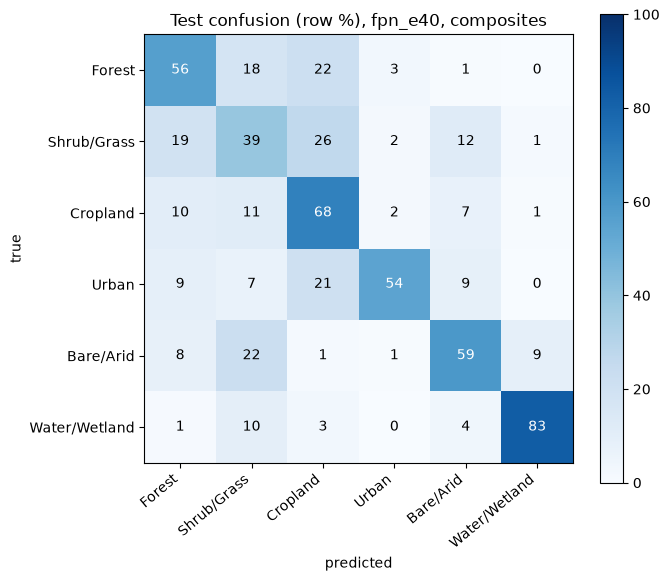

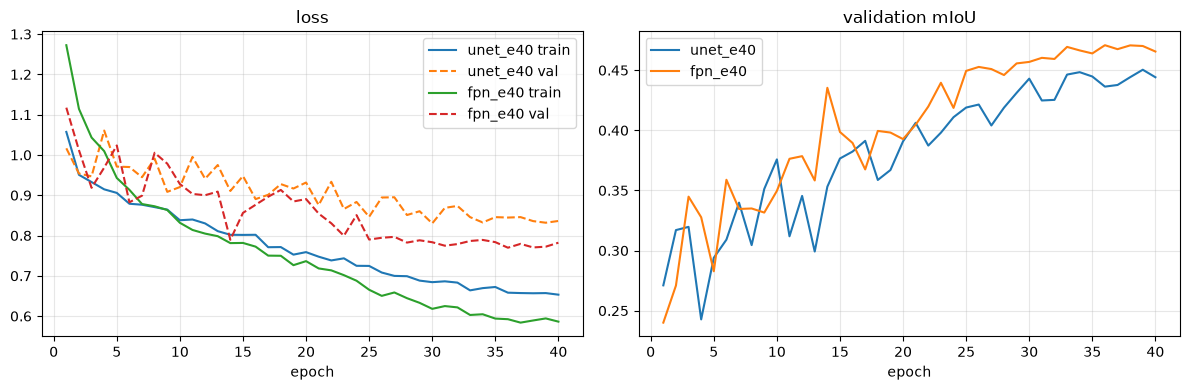

weights backed up to Drive; figures in /Users/shrutibhandari/lulc_local/d2025/figures


In [27]:
import shutil
import matplotlib.pyplot as plt

FIG = f'{LOCAL}/figures'; os.makedirs(FIG, exist_ok=True)
RUNS  = {'unet_baseline': ('unet', 'best_unet.pt'), 'fpn_k10': ('fpn', 'best_fpn_k10.pt'),
         'unet_e40': ('unet', 'best_unet_e40.pt'),  'fpn_e40': ('fpn', 'best_fpn_e40.pt')}
FINAL = ['unet_e40', 'fpn_e40']                       # equal-budget variants

def load(arch, f):
    m = build(arch); m.load_state_dict(torch.load(f'{LOCAL}/weights/{f}', map_location=dev)); return m.eval()

@torch.no_grad()
def loc_confs(m, items):                              # per-location confusion vectors (36,)
    names, confs, pos = [it[0] for it in items], {}, 0
    for x, y in DataLoader(Ds(items, False), batch_size=32):
        p, y = m(x.to(dev)).argmax(1).cpu(), y.cpu()
        for b in range(len(x)):
            v = y[b] != 255
            c = torch.bincount(y[b][v] * NC + p[b][v], minlength=NC * NC).double()
            confs[names[pos + b]] = confs.get(names[pos + b], 0) + c
        pos += len(x)
    return confs

def stats_of(vec):
    c = vec.reshape(NC, NC); tp = np.diag(c)
    with np.errstate(divide='ignore', invalid='ignore'):
        iou = tp / (c.sum(0) + c.sum(1) - tp); f1 = 2 * tp / (c.sum(0) + c.sum(1))
        prec, rec = tp / c.sum(0), tp / c.sum(1)
    return tp.sum() / c.sum(), iou, f1, prec, rec

def total(confs):
    return np.sum([v.numpy() for v in confs.values()], axis=0)

# ---------- 1) validation: pick the final model by composite val mIoU ----------
val_c, val_s = items_of('val', 'c'), items_of('val', 's', per_loc=20)
tab, keep = {}, {}
for name, (arch, f) in RUNS.items():
    m = load(arch, f)
    oc, ic = stats_of(total(loc_confs(m, val_c)))[:2]; os_, is_ = stats_of(total(loc_confs(m, val_s)))[:2]
    tab[name] = {'comp OA': oc, 'comp mIoU': np.nanmean(ic), 'single OA': os_, 'single mIoU': np.nanmean(is_)}
    if name in FINAL: keep[name] = m
    else: del m
print('VALIDATION (same data for every model)'); print(pd.DataFrame(tab).T.round(3).to_string())
chosen = max(FINAL, key=lambda k: tab[k]['comp mIoU'])
print(f'\n>>> selection rule: highest composite val mIoU among {FINAL} -> FINAL MODEL = {chosen}')

# ---------- 2) test set ----------
test_c, test_s = items_of('test', 'c'), items_of('test', 's', per_loc=20)
print(f'\nTEST: {int((df.split=="test").sum())} locations | composites {len(test_c)} | singles {len(test_s)}')
res = {k: {'c': loc_confs(m, test_c), 's': loc_confs(m, test_s)} for k, m in keep.items()}
for k in FINAL:
    for kind, lab in (('c', 'monthly composites'), ('s', 'single passes')):
        oa, iou, f1, prec, rec = stats_of(total(res[k][kind]))
        print(f'\n[{k}] {lab}: OA {oa:.3f} | mIoU {np.nanmean(iou):.3f}')
        if k == chosen:
            print(pd.DataFrame({'IoU': iou, 'F1': f1, 'precision': prec, 'recall': rec},
                               index=CLASS_NAMES).round(3).to_string())

# ---------- 3) bootstrap over test LOCATIONS ----------
def bootstrap(kind, n_boot=1000, seed=0):
    locs = sorted(set.intersection(*[set(res[k][kind]) for k in FINAL]))
    A = {k: np.stack([res[k][kind][l].numpy() for l in locs]) for k in FINAL}
    rng, out = np.random.default_rng(seed), {k: [] for k in FINAL}
    for _ in range(n_boot):
        idx = rng.integers(0, len(locs), len(locs))
        for k in FINAL:
            out[k].append(np.nanmean(stats_of(A[k][idx].sum(0))[1]))
    return {k: np.array(v) for k, v in out.items()}, len(locs)
for kind, lab in (('c', 'composites'), ('s', 'single passes')):
    b, nl = bootstrap(kind)
    print(f'\nBootstrap over {nl} test locations ({lab}), mIoU 95% interval:')
    for k in FINAL:
        print(f'  {k:9s} {np.nanmean(b[k]):.3f}  [{np.nanpercentile(b[k], 2.5):.3f}, {np.nanpercentile(b[k], 97.5):.3f}]')
    d = b['fpn_e40'] - b['unet_e40']
    print(f'  FPN minus UNet: {np.nanmean(d):+.3f}  [{np.nanpercentile(d, 2.5):+.3f}, {np.nanpercentile(d, 97.5):+.3f}]')

# ---------- 4) held-out region (Australia) ----------
reg_c = items_of('region_test', 'c')
print(f'\nREGION TEST (Australia, {int((df.split=="region_test").sum())} locations, composites) - 82% of pixels are Shrub/Grass, so only OA and that class are meaningful:')
for k in FINAL:
    oa, iou, f1, prec, rec = stats_of(total(loc_confs(keep[k], reg_c)))
    print(f'  {k:9s} OA {oa:.3f} | Shrub/Grass IoU {iou[1]:.3f}, recall {rec[1]:.3f}')

# ---------- 5) figures + backup ----------
conf = total(res[chosen]['c']).reshape(NC, NC)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(conf / conf.sum(1, keepdims=True) * 100, cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(NC)); ax.set_xticklabels(CLASS_NAMES, rotation=40, ha='right')
ax.set_yticks(range(NC)); ax.set_yticklabels(CLASS_NAMES)
for i in range(NC):
    for j in range(NC):
        ax.text(j, i, f'{conf[i, j] / conf[i].sum() * 100:.0f}', ha='center', va='center',
                color='white' if conf[i, j] / conf[i].sum() > .5 else 'black')
ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'Test confusion (row %), {chosen}, composites')
plt.colorbar(im); plt.tight_layout(); plt.savefig(f'{FIG}/confusion_{chosen}.png', dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k in FINAL:
    h = pd.read_csv(f'{LOCAL}/weights/history_{k}.csv')
    ax[0].plot(h.epoch, h.train_loss, label=f'{k} train'); ax[0].plot(h.epoch, h.val_loss, '--', label=f'{k} val')
    ax[1].plot(h.epoch, h.val_mIoU, label=k)
ax[0].set_title('loss'); ax[1].set_title('validation mIoU'); ax[0].legend(); ax[1].legend()
for a in ax: a.set_xlabel('epoch'); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{FIG}/training_curves.png', dpi=150); plt.show()

for k in FINAL:
    shutil.copy(f'{LOCAL}/weights/best_{k}.pt', f'{BASE_DIR}/dataset_v3/best_{k}.pt')
print('weights backed up to Drive; figures in', FIG)

## Part 7: First prototype runs

A first monthly prototype: downloads Sentinel-1 for 12 months of 2025 at Heidelberg, predicts a land-cover map per month, and prints the class shares, the month-to-month change and the total change. Earth Engine returned temporary 503 errors, which the retry logic handled.

   retry 1/5 in 3s (503 Server Error: Service Unavailable for url: https://earth)

Heidelberg, 12 months (176s) - class share of valid pixels (%):
         Forest  Shrub/Grass  Cropland  Urban  Bare/Arid  Water/Wetland  passes
2025-01    22.8          5.0      46.9   24.8        0.0            0.5       8
2025-02    20.5          8.0      40.6   30.7        0.0            0.2       7
2025-03    43.4          4.1      28.6   23.5        0.0            0.4       8
2025-04    38.5         25.6      11.0   24.9        0.0            0.1       7
2025-05    25.0         27.9      28.0   19.1        0.0            0.1      15
2025-06    42.6         23.2      15.4   18.5        0.0            0.2      15
2025-07    41.1         32.7       6.8   19.2        0.0            0.1      16
2025-08    36.9         15.0      26.9   20.9        0.1            0.2      15
2025-09    17.6          6.7      55.3   19.6        0.4            0.5      16
2025-10    23.7          7.6      44.0   24.5        

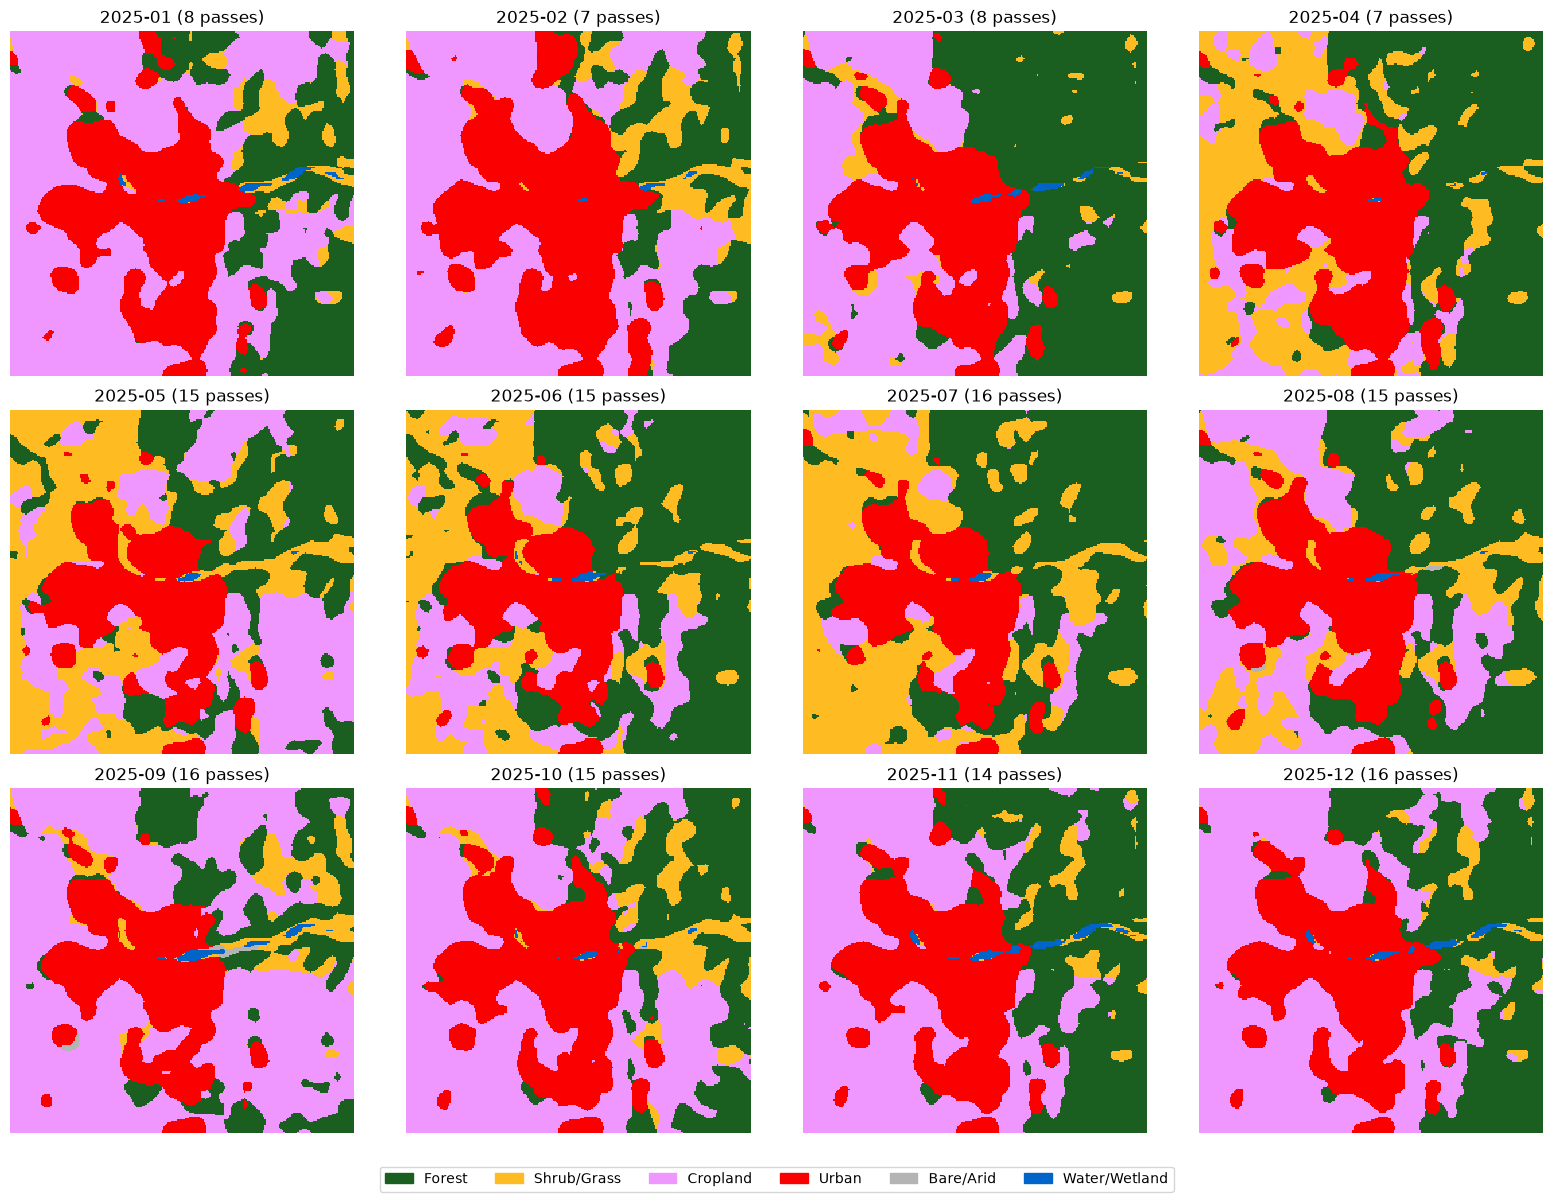

In [28]:
import time, requests, io

def fetch_pixels(img, region, tries=5):
    last = None
    for a in range(tries):
        try:
            url = img.getDownloadURL({'region': region, 'scale': 10, 'format': 'NPY', 'bands': ['VV', 'VH']})
            r = requests.get(url, timeout=300); r.raise_for_status()
            return np.load(io.BytesIO(r.content))
        except Exception as e:
            last = e; wait = 3 * 2 ** a
            print(f'   retry {a+1}/{tries} in {wait}s ({str(e)[:60]})'); time.sleep(wait)
    raise RuntimeError(f'download failed after {tries} tries: {last}')

def monthly_composite(lat, lon, year, month):
    ny, nm = (year + 1, 1) if month == 12 else (year, month + 1)
    region = ee.Geometry.Point([lon, lat]).buffer(5000).bounds()
    col = (ee.ImageCollection('COPERNICUS/S1_GRD')
           .filterDate(f'{year}-{month:02d}-01', f'{ny}-{nm:02d}-01').filterBounds(region)
           .filter(ee.Filter.eq('instrumentMode', 'IW'))
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')))
    n = col.size().getInfo()
    if n == 0:
        return None, 0
    img = col.select(['VV', 'VH', 'angle']).map(_offset).select(['VV', 'VH']).median().unmask(0)
    arr = fetch_pixels(img, region)
    a = np.stack([np.array(PILImage.fromarray(arr[b].astype(np.float32)).resize((256, 256), PILImage.NEAREST))
                  for b in ('VV', 'VH')])
    a[:, (a == 0).any(axis=0)] = np.nan
    a = np.clip(a, -60, 40)
    return (None if np.isnan(a).mean() > 0.5 else a), n

CACHE = {}
def run_prototype(lat, lon, start_year, start_month, n_months=12):
    out, y, m = [], start_year, start_month
    for _ in range(n_months):
        key = (round(lat, 4), round(lon, 4), y, m)
        if key not in CACHE:
            a, n = monthly_composite(lat, lon, y, m)
            CACHE[key] = {'n_passes': n, 'map': None if a is None else predict_map(a)}
        out.append({'label': f'{y}-{m:02d}', **CACHE[key]})
        y, m = (y + 1, 1) if m == 12 else (y, m + 1)
    return out

t0 = time.time()
res = run_prototype(*HEID, 2025, 1)
pct, step, total = summarize(res)
print(f'\nHeidelberg, 12 months ({time.time()-t0:.0f}s) - class share of valid pixels (%):')
print(pd.concat([pct.round(1), pd.Series([r["n_passes"] for r in res], index=pct.index, name='passes')], axis=1).to_string())
print('\nmonth-to-month change (percentage points):'); print(step.round(1).to_string())
print('\ntotal change, first to last valid month (pp):'); print(total.round(1).to_string())

fig, axes = plt.subplots(3, 4, figsize=(16, 12)); cm = ListedColormap(CLASS_COLORS)
for ax, r in zip(axes.ravel(), res):
    if r['map'] is None:
        ax.text(.5, .5, 'no data', ha='center'); ax.axis('off'); continue
    ax.imshow(np.where(r['map'] == 255, np.nan, r['map']), cmap=cm, vmin=0, vmax=5, interpolation='nearest')
    ax.set_title(f"{r['label']} ({r['n_passes']} passes)"); ax.axis('off')
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in CLASS_COLORS], labels=CLASS_NAMES, loc='lower center', ncol=6)
plt.tight_layout(rect=[0, .04, 1, 1]); plt.savefig(f'{FIG}/heidelberg_12months.png', dpi=150); plt.show()

Compares the prototype at Heidelberg with CORINE 2018 and with WorldCover 2021, month by month. The per-month overall accuracy against CORINE ranges from 0.39 to 0.77; the majority vote of the 12 monthly maps reaches 0.70.

   landcover: raw array (1006, 1002)
CORINE codes in the box (% of box): {111: 3.4, 112: 18.4, 121: 8.1, 142: 1.8, 211: 27.1, 221: 0.4, 222: 3.2, 231: 1.3, 311: 22.7, 312: 7.1, 313: 4.4, 511: 2.1}
excluded / unmapped codes: [142]
   Map: raw array (1006, 1002)

class share of valid pixels (%):
               CORINE 2018  WorldCover 2021 (training source)  prototype, majority of 12 months  prototype, mean of 12 months
Forest                34.8                               49.4                              35.2                          31.4
Shrub/Grass            1.3                                9.1                               6.9                          13.5
Cropland              31.3                               18.1                              35.1                          32.1
Urban                 30.5                               21.7                              22.5                          22.6
Bare/Arid              0.0                                0.1              

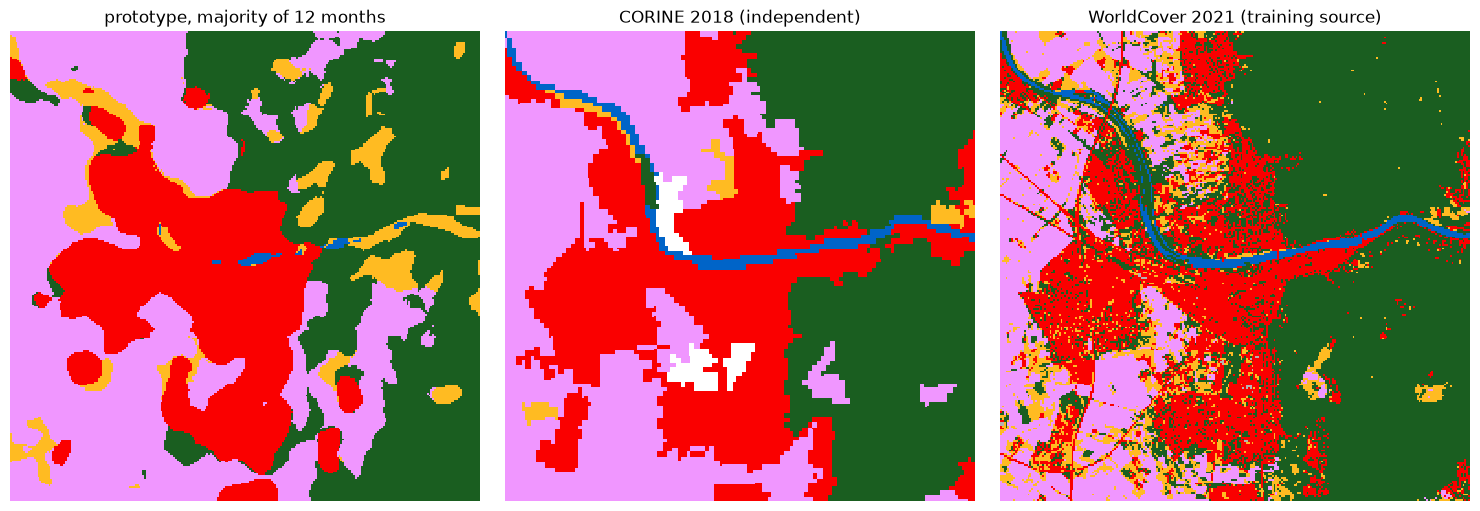

In [29]:
import io, time, requests
import numpy as np, ee
from PIL import Image as PILImage
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# CORINE codes -> our 6 classes; anything not listed is excluded as ambiguous (masked out)
CLC_TO_6 = {111:3, 112:3, 121:3, 122:3, 123:3, 124:3,                    # artificial surfaces -> Urban
            211:2, 212:2, 213:2, 221:2, 222:2, 223:2, 241:2, 242:2,      # arable, permanent crops, mosaics -> Cropland
            231:1, 321:1, 322:1, 323:1,                                  # pastures, grassland, heath, scrub -> Shrub/Grass
            311:0, 312:0, 313:0,                                         # forests -> Forest
            331:4, 332:4, 333:4, 335:4,                                  # sand, rock, sparse, ice -> Bare/Arid
            411:5, 412:5, 421:5, 511:5, 512:5, 521:5, 522:5, 523:5}      # wetlands, water -> Water/Wetland
WC_TO_6  = {10:0, 20:1, 30:1, 40:2, 50:3, 60:4, 70:4, 80:5, 90:5, 95:5, 100:4}

region = ee.Geometry.Point([HEID[1], HEID[0]]).buffer(5000).bounds()
proj = (ee.ImageCollection('COPERNICUS/S1_GRD').filterBounds(region).filterDate('2025-06-01', '2025-07-01')
        .filter(ee.Filter.eq('instrumentMode', 'IW')).first().select('VV').projection())

def fetch_band(img, band, tries=5):
    for a in range(tries):
        try:
            url = img.getDownloadURL({'region': region, 'scale': 10, 'format': 'NPY', 'bands': [band]})
            r = requests.get(url, timeout=300); r.raise_for_status()
            arr = np.load(io.BytesIO(r.content))[band]
            print(f'   {band}: raw array {arr.shape}')
            return np.array(PILImage.fromarray(arr.astype(np.float32)).resize((256, 256), PILImage.NEAREST))
        except Exception as e:
            print(f'   retry {a+1}/{tries} ({str(e)[:60]})'); time.sleep(3 * 2 ** a)
    raise RuntimeError(f'{band} download failed')

def remap(a, table):
    out = np.full(a.shape, 255, np.uint8)
    for k, v in table.items():
        out[a == k] = v
    return out

raw = fetch_band(ee.Image('COPERNICUS/CORINE/V20/100m/2018').select('landcover').unmask(0).reproject(proj), 'landcover')
clc = remap(raw, CLC_TO_6)
codes, cnt = np.unique(raw[raw > 0], return_counts=True)
print('CORINE codes in the box (% of box):', dict(zip(codes.astype(int).tolist(), (cnt / raw.size * 100).round(1).tolist())))
print('excluded / unmapped codes:', [int(c) for c in codes if int(c) not in CLC_TO_6])
wc_raw = fetch_band(ee.ImageCollection('ESA/WorldCover/v200').first().select('Map').unmask(0).reproject(proj), 'Map')
wc = remap(wc_raw, WC_TO_6)

# prototype: majority vote across the 12 monthly maps
stack = np.stack([r['map'] for r in res if r['map'] is not None])
votes = np.stack([(stack == c).sum(0) for c in range(6)])
mode  = votes.argmax(0).astype(np.uint8); mode[votes.sum(0) == 0] = 255

def agree(pred, ref):
    v = (pred != 255) & (ref != 255)
    cm = np.bincount(ref[v].astype(int) * 6 + pred[v].astype(int), minlength=36).reshape(6, 6).astype(float)
    tp = np.diag(cm)
    with np.errstate(divide='ignore', invalid='ignore'):
        iou = tp / (cm.sum(0) + cm.sum(1) - tp)
    return tp.sum() / cm.sum(), iou, int(v.sum())

def shares(m):
    v = m != 255
    return np.bincount(m[v], minlength=6) / v.sum() * 100

print('\nclass share of valid pixels (%):')
print(pd.DataFrame({'CORINE 2018': shares(clc), 'WorldCover 2021 (training source)': shares(wc),
                    'prototype, majority of 12 months': shares(mode),
                    'prototype, mean of 12 months': pct.mean().values}, index=CLASS_NAMES).round(1).to_string())

print('\npixel agreement (OA, and IoU of classes present in both):')
for name, (p, r) in {'prototype(mode) vs CORINE': (mode, clc), 'prototype(mode) vs WorldCover': (mode, wc),
                     'CORINE vs WorldCover': (clc, wc)}.items():
    oa, iou, n = agree(p, r)
    print(f'  {name:32s} OA {oa:.3f} (n={n}) | IoU ' + ', '.join(f'{c[:5]} {iou[i]:.2f}' for i, c in enumerate(CLASS_NAMES)))

print('\nper-month prototype OA vs CORINE:')
oas = [agree(r['map'], clc)[0] if r['map'] is not None else np.nan for r in res]
print('  ' + ' '.join(f'{r["label"][5:]}:{o:.2f}' for r, o in zip(res, oas)))
print(f'  min {np.nanmin(oas):.2f} | max {np.nanmax(oas):.2f} | majority-vote map {agree(mode, clc)[0]:.2f}')

cm6 = ListedColormap(CLASS_COLORS)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a_, m, t in zip(ax, [mode, clc, wc], ['prototype, majority of 12 months', 'CORINE 2018 (independent)', 'WorldCover 2021 (training source)']):
    a_.imshow(np.where(m == 255, np.nan, m), cmap=cm6, vmin=0, vmax=5, interpolation='nearest'); a_.set_title(t); a_.axis('off')
plt.tight_layout(); plt.savefig(f'{FIG}/heidelberg_vs_references.png', dpi=150); plt.show()

### Does a majority vote over the months help?

On the validation locations (62, of which 43 have a full 12 months) a single month reaches OA 0.716 and mIoU 0.486, and the majority vote of the monthly maps OA 0.744 and mIoU 0.515. The per-location OA gain is +0.037 [+0.022, +0.052] (95% bootstrap over locations). The cell also reports the accuracy by calendar month and the change between months.

In [30]:
def cmat(pred, ref):
    v = (pred != 255) & (ref != 255)
    return np.bincount(ref[v].astype(int) * 6 + pred[v].astype(int), minlength=36).reshape(6, 6).astype(float)

def miou(c):
    tp = np.diag(c)
    with np.errstate(divide='ignore', invalid='ignore'):
        return float(np.nanmean(tp / (c.sum(0) + c.sum(1) - tp)))

def oa(c):
    return np.trace(c) / c.sum()

def eval_split(split, min_months=6):
    names = [n for n in df[df.split == split].name if len(meta[n]['months']) >= min_months]
    c_single, c_mode = np.zeros((6, 6)), np.zeros((6, 6))
    c_month = {m: np.zeros((6, 6)) for m in range(1, 13)}
    rows = []
    for n in names:
        comp = np.load(f'{LOCAL}/composites/{n}.npy').astype(np.float32)
        months, y = meta[n]['months'], labs[n]
        maps = [predict_map(comp[i]) for i in range(len(months))]
        st = np.stack(maps)
        votes = np.stack([(st == c).sum(0) for c in range(6)])
        mode = votes.argmax(0).astype(np.uint8); mode[votes.sum(0) == 0] = 255
        oas = []
        for m, p in zip(months, maps):
            c = cmat(p, y); c_single += c; c_month[m] += c; oas.append(oa(c) if c.sum() else np.nan)
        cm_ = cmat(mode, y); c_mode += cm_
        row = {'name': n, 'oa_single': np.nanmean(oas), 'oa_mode': oa(cm_) if cm_.sum() else np.nan,
               'n_months': len(months), 'tv_step': np.nan, 'tv_total': np.nan}
        if len(months) == 12:                          # churn needs a full, comparable year
            ok = (y != 255) & (st != 255).all(0)
            if ok.sum() > 1000:
                S = np.stack([np.bincount(p[ok], minlength=6) / ok.sum() * 100 for p in maps])
                row['tv_step']  = float((0.5 * np.abs(np.diff(S, axis=0)).sum(1)).mean())   # % of area apparently changing per month
                row['tv_total'] = float(0.5 * np.abs(S[-1] - S[0]).sum())                   # first -> last month
        rows.append(row)
    return pd.DataFrame(rows), c_single, c_mode, c_month

dv, cs, cmo, cmm = eval_split('val')
print(f'val locations used: {len(dv)} | with a full 12 months: {int(dv.tv_step.notna().sum())}')
print(f'\npooled single-month maps : OA {oa(cs):.3f} | mIoU {miou(cs):.3f}')
print(f'pooled majority-vote maps: OA {oa(cmo):.3f} | mIoU {miou(cmo):.3f}')
d = (dv.oa_mode - dv.oa_single).dropna().values
bs = [rng_.choice(d, len(d)).mean() for rng_ in [np.random.default_rng(i) for i in range(1000)]]
print(f'per-location OA gain of majority vote over the average single month: {d.mean():+.3f} '
      f'[{np.percentile(bs, 2.5):+.3f}, {np.percentile(bs, 97.5):+.3f}]  (95% bootstrap over locations)')

print('\naccuracy by calendar month (pooled over val locations):')
print(pd.DataFrame({m: {'maps': int(c.sum() > 0), 'OA': oa(c) if c.sum() else np.nan, 'mIoU': miou(c) if c.sum() else np.nan}
                    for m, c in cmm.items()}).T[['OA', 'mIoU']].round(3).T.to_string())

print('\napparent change on locations with static labels (true change is near zero):')
print(f'  month-to-month: median {dv.tv_step.median():.1f}% of area per month '
      f'(25th-75th pct {dv.tv_step.quantile(.25):.1f}-{dv.tv_step.quantile(.75):.1f})')
print(f'  first -> last month: median {dv.tv_total.median():.1f}% of area '
      f'(25th-75th pct {dv.tv_total.quantile(.25):.1f}-{dv.tv_total.quantile(.75):.1f})')

cov = np.zeros(13)
for n in df[df.split == 'train'].name:
    for m in meta[n]['months']:
        cov[m] += 1
print('\ntraining composites per calendar month:', {m: int(cov[m]) for m in range(1, 13)})

val locations used: 62 | with a full 12 months: 43

pooled single-month maps : OA 0.716 | mIoU 0.486
pooled majority-vote maps: OA 0.744 | mIoU 0.515
per-location OA gain of majority vote over the average single month: +0.037 [+0.022, +0.052]  (95% bootstrap over locations)

accuracy by calendar month (pooled over val locations):
         1      2      3      4      5      6      7      8      9      10     11     12
OA    0.729  0.720  0.745  0.743  0.684  0.701  0.696  0.713  0.741  0.726  0.721  0.673
mIoU  0.479  0.471  0.526  0.517  0.471  0.472  0.471  0.486  0.514  0.500  0.495  0.444

apparent change on locations with static labels (true change is near zero):
  month-to-month: median 3.3% of area per month (25th-75th pct 0.0-12.4)
  first -> last month: median 0.6% of area (25th-75th pct 0.0-8.2)

training composites per calendar month: {1: 223, 2: 223, 3: 241, 4: 265, 5: 280, 6: 276, 7: 285, 8: 290, 9: 288, 10: 289, 11: 268, 12: 264}


## Part 8: Annual context channels

> **Record only, do not run.** Trains and overwrites the context-model weights.

Adds the annual mean and spread of VV and VH as extra channels (six input channels in total). Validation: composites OA 0.810 and mIoU 0.592 against 0.714 and 0.487 without context. This is the idea that the final project (separate notebook) carries on.

In [31]:
# RECORD ONLY: this cell was run once during the earlier attempt and is disabled. Do not run it again (it overwrites the context-model weights).
raise RuntimeError('RECORD ONLY: this cell writes or overwrites files. It was run once and is disabled.')
# --- original code below, kept as a record of what was run ---
import os, json, time, warnings
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
import numpy as np, pandas as pd, torch
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader

# needs the 40-epoch Cell 3 run in this kernel: df, meta, labs, MEAN, STD, LOCAL, dev, NC, CLASS_NAMES,
# make_train_items, items_of, loss_fn, val_items, SEED, K, BS, LR
TAG, ARCH, EPOCHS, PATIENCE, STD_SCALE = 'fpn_ctx_e40', 'fpn', 40, 10, 3.0   # STD_SCALE is a rough scaling (dB), not tuned

CTX = {}                                                      # per-location annual mean/std of the monthly composites
for n in df['name']:
    c = np.array(np.load(f'{LOCAL}/composites/{n}.npy', mmap_mode='r'), dtype=np.float32)   # (months, 2, 256, 256)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        am, asd = np.nanmean(c, axis=0), np.nanstd(c, axis=0)
    CTX[n] = np.concatenate([(am - MEAN) / STD, asd / STD_SCALE]).astype(np.float16)       # (4, 256, 256), NaN kept
print('context features ready:', len(CTX))

class DsCtx(Dataset):
    def __init__(self, items, train):
        self.items, self.train = items, train
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        n, kind, j = self.items[i]
        src = 'singles' if kind == 's' else 'composites'
        x = np.array(np.load(f'{LOCAL}/{src}/{n}.npy', mmap_mode='r')[j], dtype=np.float32)
        bad = np.isnan(x).any(axis=0)
        x = np.nan_to_num(np.concatenate([(x - MEAN) / STD, CTX[n].astype(np.float32)]), nan=0.0)   # 6 channels
        y = labs[n].astype(np.int64).copy(); y[bad] = 255
        if self.train:
            if np.random.rand() < .5: x, y = x[:, :, ::-1], y[:, ::-1]
            if np.random.rand() < .5: x, y = x[:, ::-1, :], y[::-1, :]
            k = np.random.randint(4)
            x, y = np.rot90(x, k, axes=(1, 2)), np.rot90(y, k, axes=(0, 1))
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y))

def summ(conf):
    tp = conf.diag(); iou = (tp / (conf.sum(0) + conf.sum(1) - tp)).numpy()
    return (tp.sum() / conf.sum()).item(), float(np.nanmean(iou)), iou

@torch.no_grad()
def evaluate_ctx(m, items):
    m.eval(); conf, tot, n = torch.zeros(NC * NC, dtype=torch.long), 0.0, 0
    for x, y in DataLoader(DsCtx(items, False), batch_size=32):
        x, y = x.to(dev), y.to(dev)
        lg = m(x); tot += loss_fn(lg, y).item() * len(x); n += len(x)
        p, yc = lg.argmax(1).cpu(), y.cpu(); v = yc != 255
        conf += torch.bincount(yc[v] * NC + p[v], minlength=NC * NC)
    return tot / n, conf.view(NC, NC).double()

torch.manual_seed(SEED); np.random.seed(SEED)
model = (smp.FPN('resnet50', encoder_weights=None, in_channels=6, classes=NC) if ARCH == 'fpn'
         else smp.Unet('resnet34', encoder_weights=None, in_channels=6, classes=NC)).to(dev)
opt   = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
rng   = np.random.default_rng(SEED + 1)
json.dump({'tag': TAG, 'arch': ARCH, 'in_channels': 6, 'std_scale': STD_SCALE, 'K': K, 'epochs': EPOCHS,
           'patience': PATIENCE, 'lr': LR, 'bs': BS, 'seed': SEED}, open(f'{LOCAL}/weights/config_{TAG}.json', 'w'))

history, best, bad, best_path = [], -1, 0, f'{LOCAL}/weights/best_{TAG}.pt'
print(f'\n########## {TAG} ##########')
for ep in range(1, EPOCHS + 1):
    model.train(); t0, tl, nb = time.time(), 0.0, 0
    for x, y in DataLoader(DsCtx(make_train_items(rng), True), batch_size=BS, shuffle=True, drop_last=True):
        x, y = x.to(dev), y.to(dev)
        opt.zero_grad(); l = loss_fn(model(x), y); l.backward(); opt.step()
        tl += l.item(); nb += 1
    sched.step()
    vl, conf = evaluate_ctx(model, val_items); oa, miou, iou = summ(conf)
    history.append({'epoch': ep, 'train_loss': tl / nb, 'val_loss': vl, 'val_OA': oa, 'val_mIoU': miou,
                    **{f'iou_{c}': float(iou[i]) for i, c in enumerate(CLASS_NAMES)}})
    pd.DataFrame(history).to_csv(f'{LOCAL}/weights/history_{TAG}.csv', index=False)
    flag = ''
    if miou > best:
        best, bad = miou, 0; torch.save(model.state_dict(), best_path); flag = ' *best*'
    else:
        bad += 1
    print(f'ep {ep:2d} | {time.time()-t0:4.0f}s | train {tl/nb:.3f} | val {vl:.3f} | OA {oa:.3f} | mIoU {miou:.3f}{flag}')
    if bad >= PATIENCE:
        print('early stop'); break

# same-footing comparison on validation (all composites; 20 singles per location)
model.load_state_dict(torch.load(best_path, map_location=dev))
res = {}
for kind, items in (('comp', items_of('val', 'c')), ('single', items_of('val', 's', per_loc=20))):
    _, conf = evaluate_ctx(model, items); res[kind] = summ(conf)
base = {'comp': (0.714, 0.487), 'single': (0.696, 0.452)}          # fpn_e40, from the earlier comparison table
print('\nVALIDATION, same data as before:')
print(f'{"":14s} {"OA":>6s} {"mIoU":>6s}')
for kind in ('comp', 'single'):
    print(f'fpn_e40 {kind:6s} {base[kind][0]:6.3f} {base[kind][1]:6.3f}')
    print(f'{TAG} {kind:6s} {res[kind][0]:6.3f} {res[kind][1]:6.3f}')
print('per-class IoU on val composites:', {c: round(float(v), 3) for c, v in zip(CLASS_NAMES, res['comp'][2])})

context features ready: 448

########## fpn_ctx_e40 ##########
ep  1 |   73s | train 1.182 | val 0.729 | OA 0.741 | mIoU 0.500 *best*
ep  2 |   74s | train 0.941 | val 0.690 | OA 0.761 | mIoU 0.522 *best*
ep  3 |   73s | train 0.848 | val 0.806 | OA 0.712 | mIoU 0.427
ep  4 |   72s | train 0.792 | val 0.846 | OA 0.714 | mIoU 0.413
ep  5 |   74s | train 0.751 | val 0.830 | OA 0.674 | mIoU 0.462
ep  6 |   74s | train 0.717 | val 0.843 | OA 0.677 | mIoU 0.414
ep  7 |   72s | train 0.676 | val 0.685 | OA 0.745 | mIoU 0.502
ep  8 |   74s | train 0.644 | val 0.734 | OA 0.692 | mIoU 0.467
ep  9 |   73s | train 0.637 | val 0.709 | OA 0.729 | mIoU 0.462
ep 10 |   72s | train 0.593 | val 0.629 | OA 0.768 | mIoU 0.534 *best*
ep 11 |   72s | train 0.602 | val 0.680 | OA 0.725 | mIoU 0.496
ep 12 |   74s | train 0.564 | val 0.658 | OA 0.777 | mIoU 0.542 *best*
ep 13 |   75s | train 0.552 | val 0.638 | OA 0.765 | mIoU 0.548 *best*
ep 14 |   73s | train 0.514 | val 0.593 | OA 0.790 | mIoU 0.565 *best*

Final comparison of the three models on validation and test. Test, composites: UNet mIoU 0.426, FPN 0.429, **FPN with context 0.526** (OA 0.712). The difference between FPN with context and FPN is +0.096 [−0.006, +0.199]. In the Australian region the context model is worse (OA 0.486 against 0.633; an always-majority-class guess reaches 0.813).

VALIDATION composites, per-class IoU
                OA   mIoU  Forest  Shrub/  Cropla  Urban  Bare/A  Water/
unet_e40     0.686  0.462   0.727   0.177   0.479  0.273   0.510   0.608
fpn_e40      0.714  0.487   0.737   0.187   0.515  0.249   0.561   0.669
fpn_ctx_e40  0.810  0.592   0.787   0.259   0.671  0.235   0.865   0.734

TEST: 63 locations | composites 691 | singles 1236
[unet_e40] composites: OA 0.583 | mIoU 0.426
[unet_e40] monthly input (singles): OA 0.616 | mIoU 0.442
[fpn_e40] composites: OA 0.594 | mIoU 0.429
[fpn_e40] monthly input (singles): OA 0.638 | mIoU 0.461
[fpn_ctx_e40] composites: OA 0.712 | mIoU 0.526
                 IoU     F1  precision  recall
Forest         0.516  0.681      0.844   0.570
Shrub/Grass    0.324  0.489      0.441   0.549
Cropland       0.597  0.747      0.687   0.819
Urban          0.378  0.549      0.473   0.655
Bare/Arid      0.770  0.870      0.865   0.876
Water/Wetland  0.569  0.725      0.962   0.582
[fpn_ctx_e40] monthly input (singles):

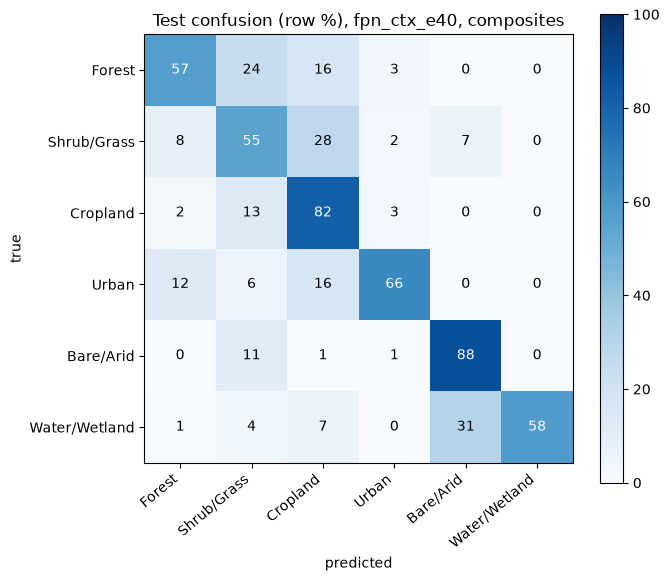

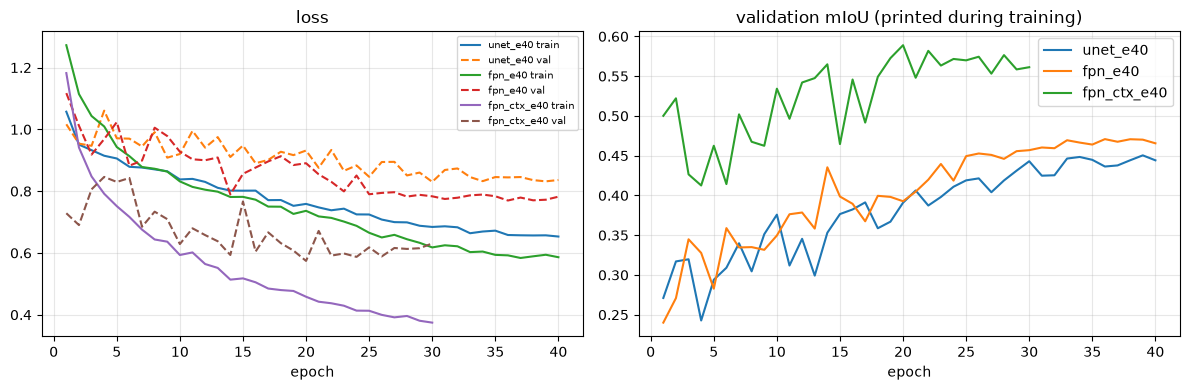

weights backed up to Drive; figures in /Users/shrutibhandari/lulc_local/d2025/figures


In [32]:
import shutil
import matplotlib.pyplot as plt

RUNS_T = {'unet_e40': ('unet', 2, Ds), 'fpn_e40': ('fpn', 2, Ds), 'fpn_ctx_e40': ('fpn', 6, DsCtx)}
CTX_TAG, REF_TAG = 'fpn_ctx_e40', 'fpn_e40'
FIG = f'{LOCAL}/figures'; os.makedirs(FIG, exist_ok=True)

def build_t(arch, cin):
    m = (smp.Unet('resnet34', encoder_weights=None, in_channels=cin, classes=NC) if arch == 'unet'
         else smp.FPN('resnet50', encoder_weights=None, in_channels=cin, classes=NC))
    return m.to(dev)

@torch.no_grad()
def t_loc_confs(m, items, DS):
    m.eval(); names, confs, pos = [it[0] for it in items], {}, 0
    for x, y in DataLoader(DS(items, False), batch_size=32):
        p, yc = m(x.to(dev)).argmax(1).cpu(), y.cpu()
        for b in range(len(x)):
            v = yc[b] != 255
            c = torch.bincount(yc[b][v] * NC + p[b][v], minlength=NC * NC).double()
            confs[names[pos + b]] = confs.get(names[pos + b], 0) + c
        pos += len(x)
    return confs

def t_total(confs):
    return np.sum([v.numpy() for v in confs.values()], axis=0)

def t_stats(vec):
    c = np.asarray(vec).reshape(NC, NC); tp = np.diag(c)
    with np.errstate(divide='ignore', invalid='ignore'):
        iou = tp / (c.sum(0) + c.sum(1) - tp); f1 = 2 * tp / (c.sum(0) + c.sum(1))
        prec, rec = tp / c.sum(0), tp / c.sum(1)
    return tp.sum() / c.sum(), iou, f1, prec, rec

M = {}
for tag, (arch, cin, DS) in RUNS_T.items():
    M[tag] = build_t(arch, cin)
    M[tag].load_state_dict(torch.load(f'{LOCAL}/weights/best_{tag}.pt', map_location=dev))

# 1) validation, same data for all three
val_c = items_of('val', 'c'); rows = {}
for tag, (arch, cin, DS) in RUNS_T.items():
    a, iou, *_ = t_stats(t_total(t_loc_confs(M[tag], val_c, DS)))
    rows[tag] = {'OA': a, 'mIoU': np.nanmean(iou), **{c[:6]: iou[i] for i, c in enumerate(CLASS_NAMES)}}
print('VALIDATION composites, per-class IoU'); print(pd.DataFrame(rows).T.round(3).to_string())

# 2) test
test_c, test_s, reg_c = items_of('test', 'c'), items_of('test', 's', per_loc=20), items_of('region_test', 'c')
R = {tag: {'c': t_loc_confs(M[tag], test_c, DS), 's': t_loc_confs(M[tag], test_s, DS), 'r': t_loc_confs(M[tag], reg_c, DS)}
     for tag, (arch, cin, DS) in RUNS_T.items()}
print(f'\nTEST: {int((df.split == "test").sum())} locations | composites {len(test_c)} | singles {len(test_s)}')
for tag in RUNS_T:
    for kind, lab in (('c', 'composites'), ('s', 'monthly input (singles)')):
        a, iou, f1, prec, rec = t_stats(t_total(R[tag][kind]))
        print(f'[{tag}] {lab}: OA {a:.3f} | mIoU {np.nanmean(iou):.3f}')
        if tag == CTX_TAG:
            print(pd.DataFrame({'IoU': iou, 'F1': f1, 'precision': prec, 'recall': rec}, index=CLASS_NAMES).round(3).to_string())

# 3) bootstrap over test locations: context model vs fpn_e40
def boot(kind, a, b, n_boot=1000, seed=0):
    locs = sorted(set(R[a][kind]) & set(R[b][kind]))
    A = np.stack([R[a][kind][l].numpy() for l in locs]); B = np.stack([R[b][kind][l].numpy() for l in locs])
    rng, da, db = np.random.default_rng(seed), [], []
    for _ in range(n_boot):
        i = rng.integers(0, len(locs), len(locs))
        da.append(np.nanmean(t_stats(A[i].sum(0))[1])); db.append(np.nanmean(t_stats(B[i].sum(0))[1]))
    return len(locs), np.array(da), np.array(db)
for kind, lab in (('c', 'composites'), ('s', 'monthly input')):
    n, da, db = boot(kind, CTX_TAG, REF_TAG); d = da - db
    print(f'\nBootstrap over {n} test locations ({lab}), mIoU 95% interval:')
    print(f'  {CTX_TAG:12s} {da.mean():.3f} [{np.percentile(da, 2.5):.3f}, {np.percentile(da, 97.5):.3f}]')
    print(f'  {REF_TAG:12s} {db.mean():.3f} [{np.percentile(db, 2.5):.3f}, {np.percentile(db, 97.5):.3f}]')
    print(f'  difference   {d.mean():+.3f} [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]')

# 4) held-out region (Australia)
print(f'\nREGION TEST (Australia, {int((df.split == "region_test").sum())} locations, composites)')
for tag in RUNS_T:
    c = t_total(R[tag]['r']).reshape(NC, NC); a, iou, f1, prec, rec = t_stats(c.ravel())
    print(f'  {tag:12s} OA {a:.3f} | always-majority-class OA {c.sum(1).max() / c.sum():.3f} | '
          f'Shrub/Grass IoU {iou[1]:.3f}, recall {rec[1]:.3f}')

# 5) figures + backup
c = t_total(R[CTX_TAG]['c']).reshape(NC, NC)
fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(c / c.sum(1, keepdims=True) * 100, cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(NC)); ax.set_xticklabels(CLASS_NAMES, rotation=40, ha='right'); ax.set_yticks(range(NC)); ax.set_yticklabels(CLASS_NAMES)
for i in range(NC):
    for j in range(NC):
        ax.text(j, i, f'{c[i, j] / c[i].sum() * 100:.0f}', ha='center', va='center', color='white' if c[i, j] / c[i].sum() > .5 else 'black')
ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'Test confusion (row %), {CTX_TAG}, composites')
plt.colorbar(im); plt.tight_layout(); plt.savefig(f'{FIG}/confusion_{CTX_TAG}.png', dpi=150); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for tag in RUNS_T:
    h = pd.read_csv(f'{LOCAL}/weights/history_{tag}.csv')
    axs[0].plot(h.epoch, h.train_loss, label=f'{tag} train'); axs[0].plot(h.epoch, h.val_loss, '--', label=f'{tag} val')
    axs[1].plot(h.epoch, h.val_mIoU, label=tag)
axs[0].set_title('loss'); axs[1].set_title('validation mIoU (printed during training)'); axs[0].legend(fontsize=7); axs[1].legend()
for a_ in axs: a_.set_xlabel('epoch'); a_.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{FIG}/training_curves_all.png', dpi=150); plt.show()
for tag in RUNS_T:
    shutil.copy(f'{LOCAL}/weights/best_{tag}.pt', f'{BASE_DIR}/dataset_v3/best_{tag}.pt')
print('weights backed up to Drive; figures in', FIG)

### Monthly maps, Australia and change noise

Australia: the confusion matrix shows that most Bare/Arid, Water/Wetland and Urban pixels are predicted as Shrub/Grass or Cropland. On the validation locations with 12 months (true change is near zero), the median month-to-month change is 3.3% of the area for FPN and 0.1% for FPN with context.

In [33]:
@torch.no_grad()
def monthly_maps(tag, n):
    comp = np.array(np.load(f'{LOCAL}/composites/{n}.npy'), dtype=np.float32)       # (months, 2, 256, 256)
    bad = np.isnan(comp).any(axis=1)
    x = np.nan_to_num((comp - MEAN) / STD, nan=0.0)
    if RUNS_T[tag][1] == 6:
        ctx = np.nan_to_num(np.repeat(CTX[n].astype(np.float32)[None], len(x), axis=0), nan=0.0)
        x = np.concatenate([x, ctx], axis=1)
    p = M[tag](torch.from_numpy(x.astype(np.float32)).to(dev)).argmax(1).cpu().numpy().astype(np.uint8)
    p[bad] = 255
    return p

TAGS = ['fpn_e40', 'fpn_ctx_e40']

# 1) Australia: confusion matrices and per-location accuracy
reg_c = items_of('region_test', 'c')
loc_c = {t: t_loc_confs(M[t], reg_c, RUNS_T[t][2]) for t in TAGS}
for t in TAGS:
    c = t_total(loc_c[t]).reshape(NC, NC); rows = c.sum(1, keepdims=True)
    print(f'\n{t}: Australia, % of true pixels predicted as each class')
    print(pd.DataFrame(c / np.where(rows == 0, 1, rows) * 100, index=CLASS_NAMES,
                       columns=[x[:5] for x in CLASS_NAMES]).round(0).astype(int).to_string())
    print('true class share (%):', dict(zip(CLASS_NAMES, (rows.ravel() / c.sum() * 100).round(0))))
oa_loc = pd.DataFrame({t: {n: np.trace(v.numpy().reshape(NC, NC)) / v.sum().item() for n, v in loc_c[t].items()} for t in TAGS})
oa_loc['diff'] = oa_loc['fpn_ctx_e40'] - oa_loc['fpn_e40']
oa_loc['lat'] = [float(df.loc[df.name == n, 'lat'].iloc[0]) for n in oa_loc.index]
oa_loc['lon'] = [float(df.loc[df.name == n, 'lon'].iloc[0]) for n in oa_loc.index]
print(f'\nper-location OA, Australia: context worse at {(oa_loc["diff"] < -0.02).sum()} locations, '
      f'better at {(oa_loc["diff"] > 0.02).sum()}, similar at {(oa_loc["diff"].abs() <= 0.02).sum()} of {len(oa_loc)}')
print(oa_loc.sort_values('diff').head(6).round(3).to_string())

# 2) apparent change on VAL locations (true change is near zero)
def churn(tag, names):
    steps, tot = [], []
    for n in names:
        if len(meta[n]['months']) != 12: continue
        st, y = monthly_maps(tag, n), labs[n]
        ok = (y != 255) & (st != 255).all(0)
        if ok.sum() < 1000: continue
        S = np.stack([np.bincount(p[ok], minlength=6) / ok.sum() * 100 for p in st])
        steps.append(0.5 * np.abs(np.diff(S, axis=0)).sum(1).mean()); tot.append(0.5 * np.abs(S[-1] - S[0]).sum())
    return np.array(steps), np.array(tot)
vn = df[df.split == 'val'].name.tolist()
print('\napparent change on val locations with 12 months (% of area, true change is near zero):')
for t in TAGS:
    s, tt = churn(t, vn)
    print(f'  {t:12s} n={len(s)} | month-to-month: median {np.median(s):.1f}, 25-75% {np.percentile(s, 25):.1f}-{np.percentile(s, 75):.1f}, '
          f'mean {s.mean():.1f} | first->last: median {np.median(tt):.1f}, mean {tt.mean():.1f}')


fpn_e40: Australia, % of true pixels predicted as each class
               Fores  Shrub  Cropl  Urban  Bare/  Water
Forest            63     28      7      0      2      0
Shrub/Grass       16     68      5      0     11      0
Cropland           0      9     90      0      0      0
Urban              4     12     83      0      0      0
Bare/Arid          9     72     16      0      2      1
Water/Wetland      1     76     22      0      0      1
true class share (%): {'Forest': np.float64(6.0), 'Shrub/Grass': np.float64(81.0), 'Cropland': np.float64(4.0), 'Urban': np.float64(0.0), 'Bare/Arid': np.float64(8.0), 'Water/Wetland': np.float64(0.0)}

fpn_ctx_e40: Australia, % of true pixels predicted as each class
               Fores  Shrub  Cropl  Urban  Bare/  Water
Forest             4     59     24      0     12      0
Shrub/Grass        0     48      8      0     44      0
Cropland           0      2     87      0     11      0
Urban              0     22     73      0      4      

### Label check against Dynamic World

Compares the WorldCover labels with Dynamic World at sample locations (agreement in %, and the Urban share in each product) to judge how reliable the training labels are. The decision was made with thresholds fixed beforehand.

In [34]:
import os, io, time, requests
import numpy as np, pandas as pd, ee
from PIL import Image as PILImage
ee.Initialize(project='friendly-aurora-426714-v0')

LOCAL = os.path.expanduser('~/lulc_local/d2025')
NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
DW_TO_6 = {1: 0, 2: 1, 5: 1, 4: 2, 6: 3, 7: 4, 8: 4, 0: 5, 3: 5}    # verified against the catalog class table
YEAR = 2025
df = pd.read_csv('split_2025.csv')
scenes = df.groupby('class').sample(2, random_state=0)               # 2 scenes per sampling tag

def dw_label(lat, lon):
    region = ee.Geometry.Point([lon, lat]).buffer(5000).bounds()      # same 10 km box as the stored label
    img = (ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1').filterDate(f'{YEAR}-01-01', f'{YEAR + 1}-01-01')
           .filterBounds(region).select('label').mode().rename('label').unmask(255).toUint8())
    for a in range(4):
        try:
            url = img.getDownloadURL({'region': region, 'scale': 10, 'format': 'NPY', 'bands': ['label']})
            r = requests.get(url, timeout=300); r.raise_for_status()
            arr = np.load(io.BytesIO(r.content))['label']
            return np.array(PILImage.fromarray(arr.astype(np.float32)).resize((256, 256), PILImage.NEAREST)).astype(np.uint8)
        except Exception:
            time.sleep(3 * (a + 1))
    return None

def remap(a):
    out = np.full(a.shape, 255, np.uint8)
    for k, v in DW_TO_6.items():
        out[a == k] = v
    return out

conf, rows = np.zeros((6, 6)), []
for _, r in scenes.iterrows():
    raw = dw_label(r['lat'], r['lon'])
    if raw is None:
        print(r['name'], 'download failed'); continue
    dw, wc = remap(raw), np.load(f'{LOCAL}/labels/{r["name"]}.npy')
    v = (dw != 255) & (wc != 255)
    conf += np.bincount(wc[v].astype(int) * 6 + dw[v].astype(int), minlength=36).reshape(6, 6)
    rows.append({'scene': r['name'], 'tag': r['class'], 'agree %': round(float((dw[v] == wc[v]).mean() * 100), 1),
                 'Urban WC %': round(float((wc[v] == 3).mean() * 100), 1), 'Urban DW %': round(float((dw[v] == 3).mean() * 100), 1)})
print(pd.DataFrame(rows).to_string(index=False))

pa = np.trace(conf) / conf.sum() * 100
print(f'\npooled agreement: {pa:.1f}% of {int(conf.sum())} pixels')
print('\nclass share of the same pixels (%):')
print(pd.DataFrame({'WorldCover 2021': conf.sum(1) / conf.sum() * 100, 'Dynamic World 2025': conf.sum(0) / conf.sum() * 100},
                   index=NAMES).round(1).to_string())
print('\nshare of each WorldCover class kept if only agreeing pixels are used (%):')
print(pd.Series(np.diag(conf) / np.maximum(conf.sum(1), 1) * 100, index=NAMES).round(0).astype(int).to_string())
print('\nrows = WorldCover class, columns = Dynamic World class (% of the WorldCover pixels):')
print(pd.DataFrame(conf / np.maximum(conf.sum(1, keepdims=True), 1) * 100, index=NAMES,
                   columns=[n[:5] for n in NAMES]).round(0).astype(int).to_string())
print('\ndecision (my thresholds, set beforehand):',
      'use agreement labels' if pa >= 75 else
      'use agreement labels, but check which classes lose the most pixels' if pa >= 60 else
      'keep WorldCover as the label source and document the year gap')

           scene         tag  agree %  Urban WC %  Urban DW %
  bare_arid_0110   bare_arid     95.5         0.0         0.0
  bare_arid_0018   bare_arid    100.0         0.0         0.0
   cropland_0087    cropland     69.5         1.0         2.6
   cropland_0066    cropland     88.0         0.1         0.6
     forest_0114      forest     85.7         0.0         0.0
     forest_0034      forest     86.5         0.3         0.0
shrub_grass_0003 shrub_grass     73.2         1.1         6.6
shrub_grass_0121 shrub_grass    100.0         0.0         0.0
      urban_0088       urban     63.9         0.0         0.1
      urban_0051       urban     79.4         0.4         1.0
      water_0082       water     26.3         0.3         1.2
      water_0004       water     49.8         0.0         0.0

pooled agreement: 76.5% of 786432 pixels

class share of the same pixels (%):
               WorldCover 2021  Dynamic World 2025
Forest                    42.8                47.6
Shrub/Grass  